# 🕐 Sesión 10-A (Práctica): LSTM vs GRU en dos datasets diferentes

**Curso:** IS056B — Ingeniería del Conocimiento | UNCP 2026-II
**Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps
**Basado en:** *Sesión 10-A: Series de Tiempo con RNN, LSTM y GRU*

---

### Objetivo
Aplicar y comparar las arquitecturas **LSTM** y **GRU** en dos series de tiempo diferentes al dataset Jena Climate usado en clase, siguiendo el mismo flujo de trabajo: exploración → split cronológico → normalización (fit solo en train) → ventanas deslizantes → modelos → evaluación contra baselines.

### Estructura del Notebook
| Parte | Dataset (Kaggle) | Tipo | Frecuencia | Tarea | Modelos |
|---|---|---|---|---|---|
| **1** | Daily Minimum Temperatures in Melbourne (1981–1990) | Univariado | Diaria | Temperatura mínima del día siguiente | LSTM vs GRU apilados (64→32) |
| **2** | Appliances Energy Prediction (2016) | Multivariado (30 variables) | Cada 10 min | Consumo eléctrico 1 hora adelante | LSTM vs GRU apilados (128→64) |
| **3** | Comparación final y conclusiones generales | | | | |

### Resultados en una línea
| Dataset | Mejor baseline (MAE) | LSTM (MAE) | GRU (MAE) | Ganador |
|---|---|---|---|---|
| Melbourne | 1.950 °C (naive t-1) | **1.746 °C** | 1.750 °C | Empate técnico (0.004 °C) |
| Appliances | 42.81 Wh (media última hora) | 39.77 Wh | **37.17 Wh** | GRU (−6.5% de MAE) |

> **Requisitos:** GPU T4 habilitada (Entorno de ejecución → Cambiar tipo de entorno → GPU T4)

---
# ⚙️ Configuración común

In [ ]:
# ============================================================
# 📦 Instalación e importaciones
# ============================================================
!pip install -q kagglehub statsmodels

import os, glob, time, warnings
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore')

np.random.seed(42)
tf.random.set_seed(42)
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print(f'TensorFlow: {tf.__version__}')
gpus = tf.config.list_physical_devices('GPU')
print(f'✅ GPU disponible: {gpus[0].name}' if gpus else '⚠️ Sin GPU: Entorno de ejecución → Cambiar tipo de entorno → GPU T4')

TensorFlow: 2.21.0
✅ GPU disponible: /physical_device:GPU:0


## 📋 Recordatorio: LSTM vs GRU

| Característica | LSTM | GRU |
|---|---|---|
| **Compuertas** | 3 (Forget, Input, Output) | 2 (Update, Reset) |
| **Estados** | 2 ($h_t$ + $C_t$) | 1 ($h_t$) |
| **Parámetros** | Más | ~25% menos |
| **Velocidad** | Más lenta | Más rápida |

**Hipótesis de trabajo:** GRU debería lograr un error similar al de LSTM con menos parámetros y menos tiempo de entrenamiento.

In [ ]:
# ============================================================
# 🛠️ Funciones auxiliares (mismas ideas del notebook de clase)
# ============================================================

def create_sequences(data, window_size, horizon=1):
    '''Crea pares (X, y) con ventanas deslizantes. El target es la columna 0.'''
    if data.ndim == 1:
        data = data.reshape(-1, 1)
    X, y = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size:i + window_size + horizon, 0])
    X, y = np.array(X, dtype='float32'), np.array(y, dtype='float32')
    if horizon == 1:
        y = y.flatten()
    return X, y


def evaluate_forecast(y_true, y_pred):
    '''MAE, RMSE y R² sobre valores ya desnormalizados.'''
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}


def build_rnn(cell, input_shape, units=(64,), dropout=0.2, dense=0, name=None):
    '''LSTM o GRU (una o más capas apiladas) con la MISMA arquitectura
    para ambos tipos de celda: así la comparación es justa.'''
    tf.random.set_seed(42)
    Cell = layers.LSTM if cell == 'LSTM' else layers.GRU
    model = models.Sequential(name=name or f'{cell}_model')
    model.add(layers.Input(shape=input_shape))
    for i, u in enumerate(units):
        model.add(Cell(u, return_sequences=(i < len(units) - 1), name=f'{cell.lower()}_{u}_{i}'))
        model.add(layers.Dropout(dropout))
    if dense:
        model.add(layers.Dense(dense, activation='relu'))
    model.add(layers.Dense(1, name='salida'))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model


def train_model(model, X, y, val=None, epochs=40, batch_size=64, verbose=0):
    '''EarlyStopping + ReduceLROnPlateau. Si no se pasa val, validation_split
    toma el ÚLTIMO 15% del train (validación también cronológica).'''
    cb = [callbacks.EarlyStopping(patience=6, restore_best_weights=True, monitor='val_loss'),
          callbacks.ReduceLROnPlateau(factor=0.5, patience=3, monitor='val_loss')]
    kw = {'validation_data': val} if val is not None else {'validation_split': 0.15}
    t0 = time.time()
    hist = model.fit(X, y, epochs=epochs, batch_size=batch_size, callbacks=cb, verbose=verbose, **kw)
    return hist, time.time() - t0


def plot_histories(hists, title):
    fig, axes = plt.subplots(1, len(hists), figsize=(8 * len(hists), 5))
    for ax, (name, h) in zip(np.atleast_1d(axes), hists.items()):
        c = COLORS[name.lower()]
        ax.plot(h.history['loss'], color=c, lw=2, label='Train')
        ax.plot(h.history['val_loss'], color=c, lw=2, ls='--', label='Val')
        ax.set_title(f'{name} — Loss'); ax.set_xlabel('Época'); ax.set_ylabel('MSE'); ax.legend()
    plt.suptitle(title, fontsize=14, fontweight='bold'); plt.tight_layout(); plt.show()


def print_table(rows, unit=''):
    print('=' * 80)
    print(f'{"Modelo":<22} {"MAE "+unit:<13} {"RMSE "+unit:<13} {"R²":<8} {"Params":<10} {"Tiempo (s)":<10}')
    print('-' * 80)
    for name, r in rows.items():
        p = f'{r["params"]:,}' if r.get('params') else '—'
        t = f'{r["time"]:.1f}' if r.get('time') else '—'
        print(f'{name:<22} {r["MAE"]:<13.3f} {r["RMSE"]:<13.3f} {r["R2"]:<8.3f} {p:<10} {t:<10}')
    print('=' * 80)


COLORS = {'lstm': '#2196F3', 'gru': '#FF9800', 'actual': '#263238',
          'naive': '#9E9E9E', 'snaive': '#8BC34A'}
print('✅ Funciones auxiliares cargadas')

✅ Funciones auxiliares cargadas


In [3]:
# ============================================================
# 🛠️ Ventanas con predicción a "ahead" pasos (específica de esta práctica)
# ============================================================
def create_sequences_ahead(data, window_size, ahead=1):
    '''X = data[i : i+window]  →  y = data[i+window+ahead-1, 0]
    ahead=1 predice el paso siguiente; ahead=6 predice 1 hora adelante (pasos de 10 min).'''
    X, y = [], []
    for i in range(len(data) - window_size - ahead + 1):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size + ahead - 1, 0])
    return np.array(X, dtype='float32'), np.array(y, dtype='float32')
print('✅ create_sequences_ahead lista')

✅ create_sequences_ahead lista


---
# 🌡️ PARTE 1: Temperaturas mínimas diarias de Melbourne (univariado)

**Dataset:** [Daily Minimum Temperatures in Melbourne](https://www.kaggle.com/datasets/paulbrabban/daily-minimum-temperatures-in-melbourne) (Kaggle). Temperatura mínima diaria de Melbourne, Australia, entre 1981 y 1990 (~3 650 días), originalmente de la Oficina de Meteorología de Australia.

**Tarea:** Forecasting univariado many-to-one. Se predice la temperatura mínima del **día siguiente** a partir de los últimos 30 días.

| | Jena (clase) | Melbourne (Parte 1) |
|---|---|---|
| Frecuencia | Cada hora | **Diaria** |
| Estacionalidad dominante | Diaria (día/noche) | **Anual** (verano/invierno, hemisferio sur) |
| Tamaño | ~70 000 horas | **~3 650 días** (dataset pequeño) |
| Ruido | Bajo hora a hora | **Alto** de un día a otro |

---
### 1.1 · Carga del dataset desde Kaggle

Usamos `kagglehub`. En lugar de `load_dataset(...)` con `file_path=""` (que exige conocer el nombre exacto del CSV), descargamos la carpeta del dataset con `dataset_download` y buscamos el CSV dentro. El resultado es el mismo y no falla si el archivo cambia de nombre.

> Si Kaggle pide autenticación: Colab → 🔑 *Secrets* → agrega `KAGGLE_USERNAME` y `KAGGLE_KEY` (desde kaggle.com → Settings → *Create New Token*).

In [ ]:
# ============================================================
# 📥 Descarga desde Kaggle
# ============================================================
path = kagglehub.dataset_download('paulbrabban/daily-minimum-temperatures-in-melbourne')
csvs = sorted(glob.glob(os.path.join(path, '**', '*.csv'), recursive=True))
print('Archivos encontrados:', [os.path.basename(c) for c in csvs])

df_raw = pd.read_csv(csvs[0], on_bad_lines='skip')
print(f'Shape original: {df_raw.shape}')
print('Columnas:', list(df_raw.columns))
print("First 5 records:")
df_raw.head()

Using Colab cache for faster access to the 'daily-minimum-temperatures-in-melbourne' dataset.
Archivos encontrados: ['daily-minimum-temperatures-in-me.csv']
Shape original: (3650, 2)
Columnas: ['Date', 'Daily minimum temperatures in Melbourne, Australia, 1981-1990']
First 5 records:


,Date,"Daily minimum temperatures in Melbourne, Australia, 1981-1990"
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


### 🧹 Limpieza
Esta versión del dataset viene "sucia" (es la exportación original de DataMarket):
- La columna de temperatura puede venir como **texto**, con algunos valores tipo `?0.2`.
- Puede traer una **fila final con la descripción** del dataset en lugar de una fecha.
- Los años bisiestos (1984 y 1988) **no tienen el 31 de diciembre**, así que faltan días.

Limpiamos todo eso para tener una serie diaria completa y continua. Las ventanas deslizantes necesitan que cada paso sea exactamente 1 día.

In [ ]:
# ============================================================
# 🧹 Limpieza y serie diaria completa
# ============================================================
df = df_raw.iloc[:, :2].copy()
df.columns = ['Date', 'Temp']
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Temp'] = pd.to_numeric(df['Temp'].astype(str).str.replace(r'[^0-9.\-]', '', regex=True),
                           errors='coerce')
filas_invalidas = df['Date'].isna().sum()
df = df.dropna(subset=['Date']).drop_duplicates('Date').set_index('Date').sort_index()

full_idx = pd.date_range(df.index.min(), df.index.max(), freq='D')
faltantes = len(full_idx) - len(df)
df = df.reindex(full_idx)
nan_temp = df['Temp'].isna().sum()
df['Temp'] = df['Temp'].interpolate()           # rellena los días faltantes

print(f'Filas sin fecha válida eliminadas: {filas_invalidas}')
print(f'Días faltantes en el calendario:   {faltantes}')
print(f'Valores interpolados en total:     {nan_temp}')
print(f'Serie final: {len(df):,} días ({df.index.min():%Y-%m-%d} → {df.index.max():%Y-%m-%d})')
df.describe().T

Filas sin fecha válida eliminadas: 0
Días faltantes en el calendario:   2
Valores interpolados en total:     2
Serie final: 3,652 días (1981-01-01 → 1990-12-31)


,count,mean,std,min,25%,50%,75%,max
Temp,3652.0,11.179587,4.071482,0.0,8.3,11.0,14.0,26.3


> 📝 **Interpretación:** el CSV trae **3 650 registros**, pero 10 años tienen 3 652 días. Faltaban **2 días** (el 31 de diciembre de 1984 y de 1988, ambos años bisiestos), que se rellenaron por interpolación. La línea de texto descriptivo al final del archivo se descartó al leerlo (`on_bad_lines='skip'`). La serie final es continua: **3 652 días, del 01/01/1981 al 31/12/1990**.

---
### 1.2 · Exploración de la serie

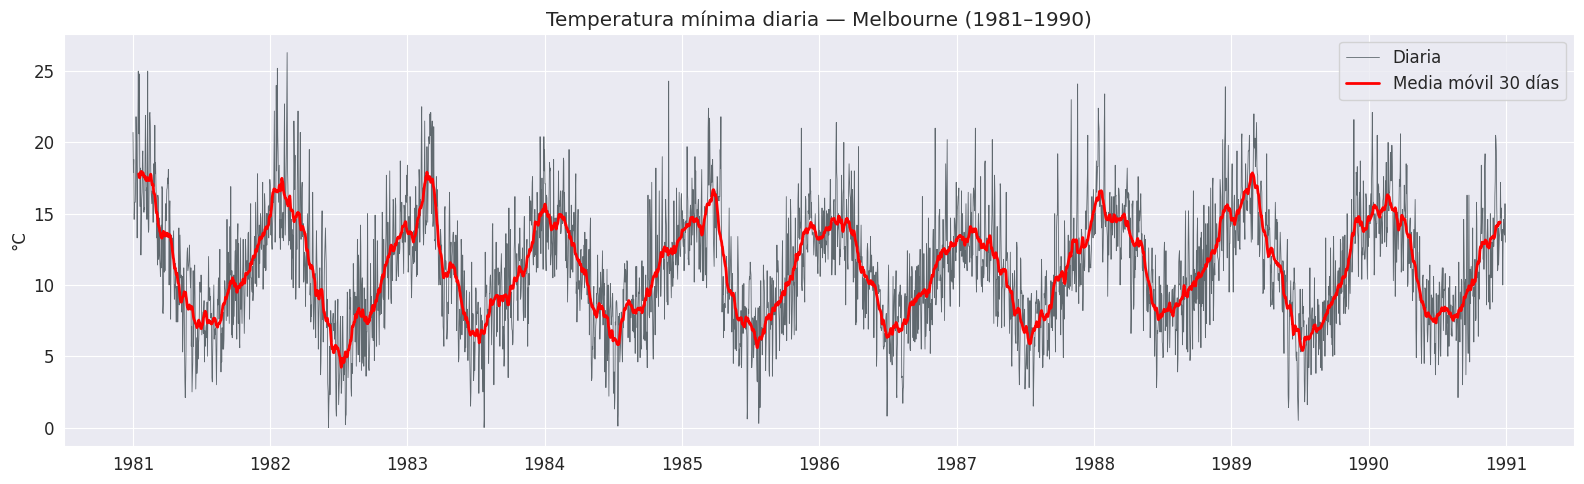

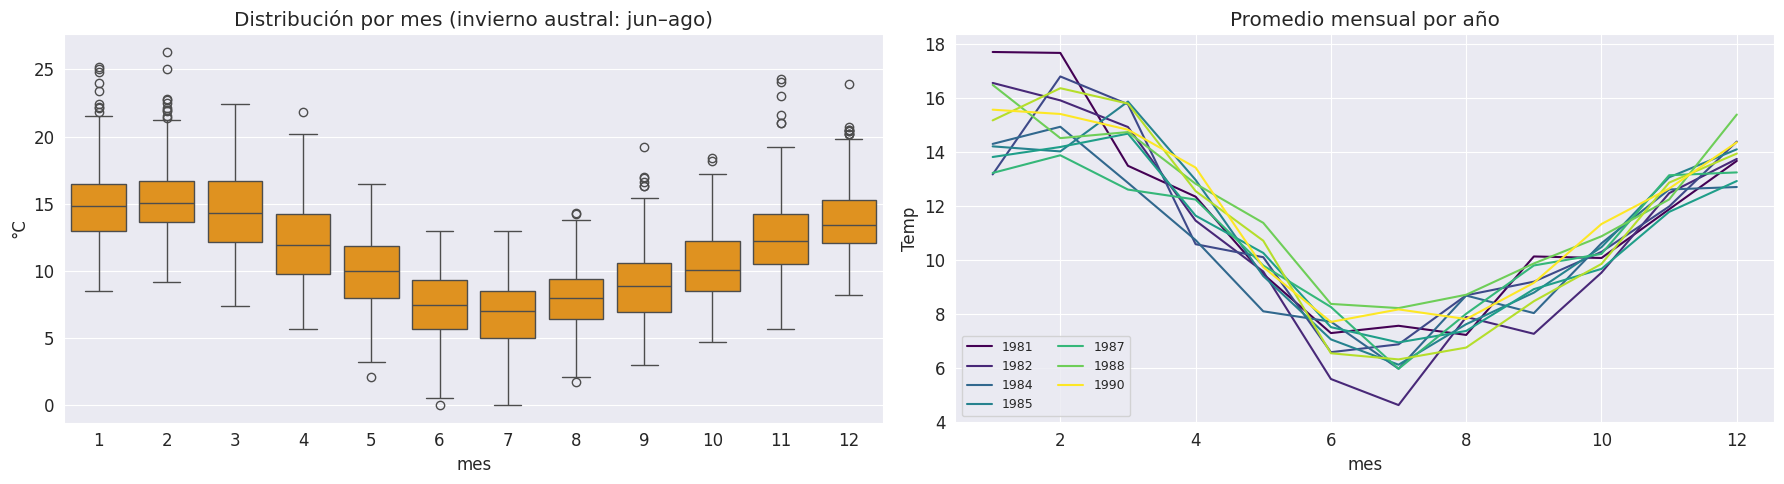

Mínima: 0.0°C | Máxima: 26.3°C | Media: 11.2°C | Desv.: 4.07°C


In [ ]:
# ============================================================
# 📈 Serie completa y patrón anual
# ============================================================
temp = df['Temp'].values.astype('float32')

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df.index, temp, color=COLORS['actual'], lw=0.6, alpha=0.7, label='Diaria')
ax.plot(df.index, pd.Series(temp).rolling(30, center=True).mean(), color='red', lw=2,
        label='Media móvil 30 días')
ax.set_title('Temperatura mínima diaria — Melbourne (1981–1990)'); ax.set_ylabel('°C'); ax.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
tmp = df.assign(mes=df.index.month, anio=df.index.year)
sns.boxplot(data=tmp, x='mes', y='Temp', ax=axes[0], color=COLORS['gru'])
axes[0].set_title('Distribución por mes (invierno austral: jun–ago)'); axes[0].set_ylabel('°C')
sns.lineplot(data=tmp.groupby(['anio', 'mes'])['Temp'].mean().reset_index(),
             x='mes', y='Temp', hue='anio', palette='viridis', ax=axes[1])
axes[1].set_title('Promedio mensual por año'); axes[1].legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

print(f'Mínima: {temp.min():.1f}°C | Máxima: {temp.max():.1f}°C | Media: {temp.mean():.1f}°C | Desv.: {temp.std():.2f}°C')

> 📝 **Interpretación:** la temperatura mínima va de **0.0 °C a 26.3 °C**, con una media de **11.2 °C** y una desviación de **4.07 °C**. Los boxplots mensuales muestran el ciclo del hemisferio sur: los meses más fríos son **junio, julio y agosto** y los más cálidos, **enero y febrero**. El patrón se repite casi igual todos los años, así que no se observa una tendencia de calentamiento en este periodo.

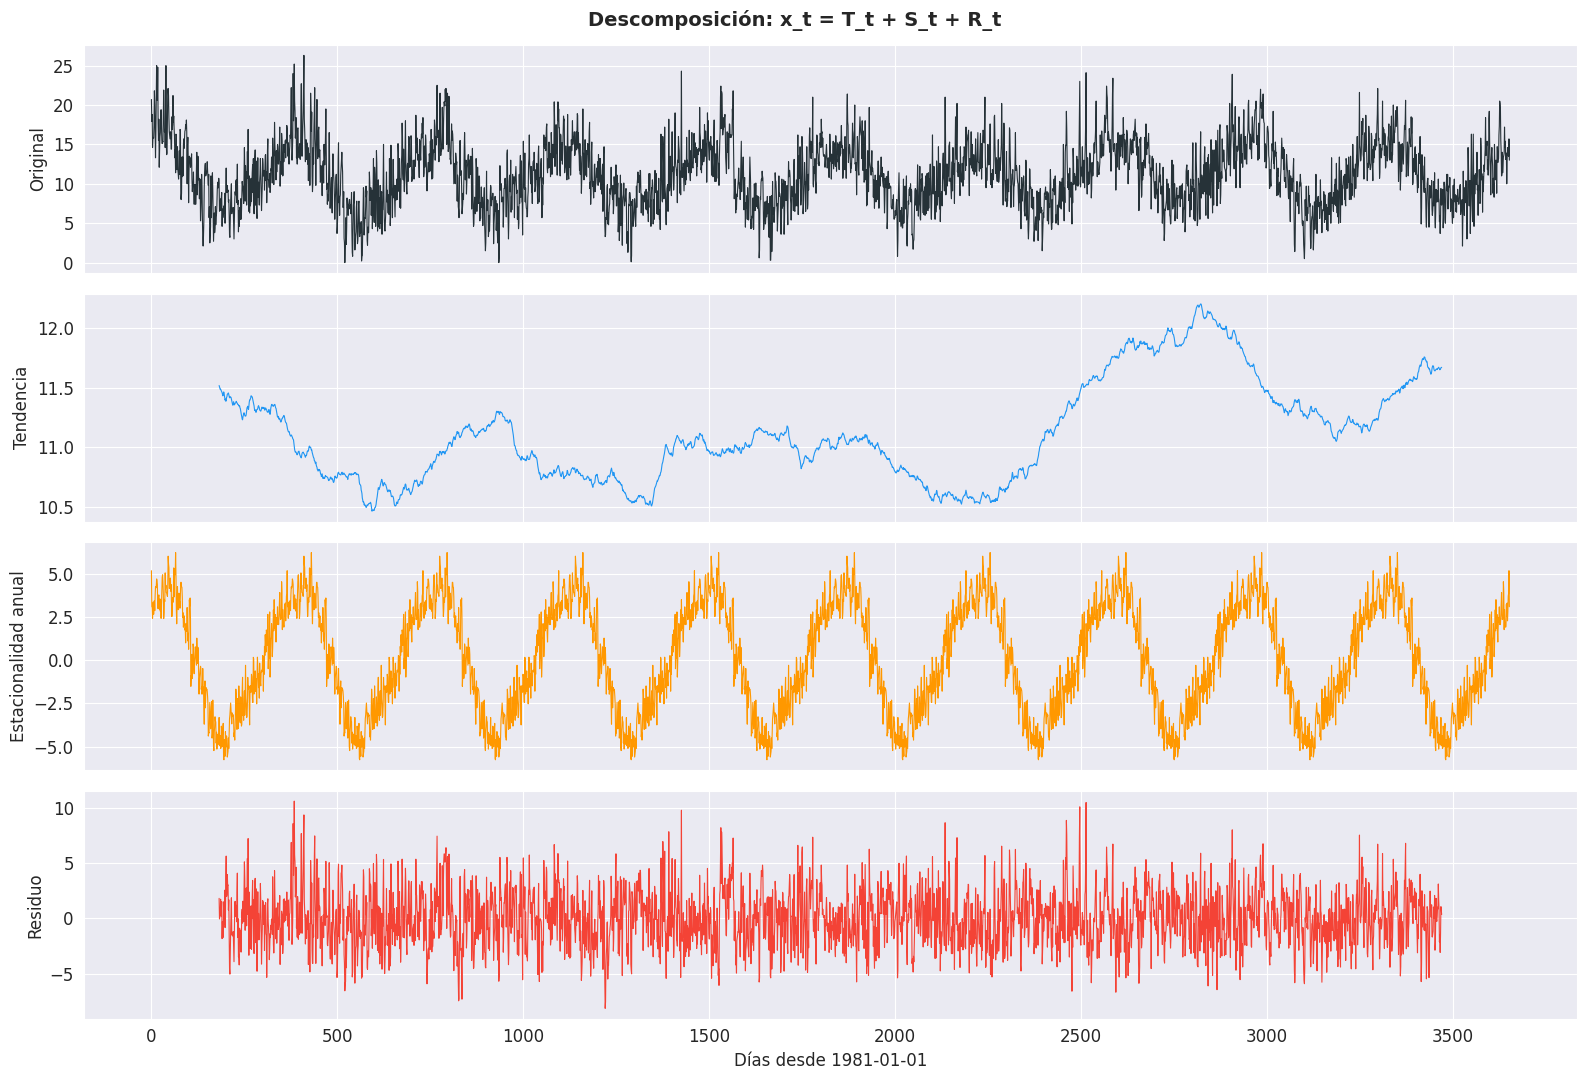

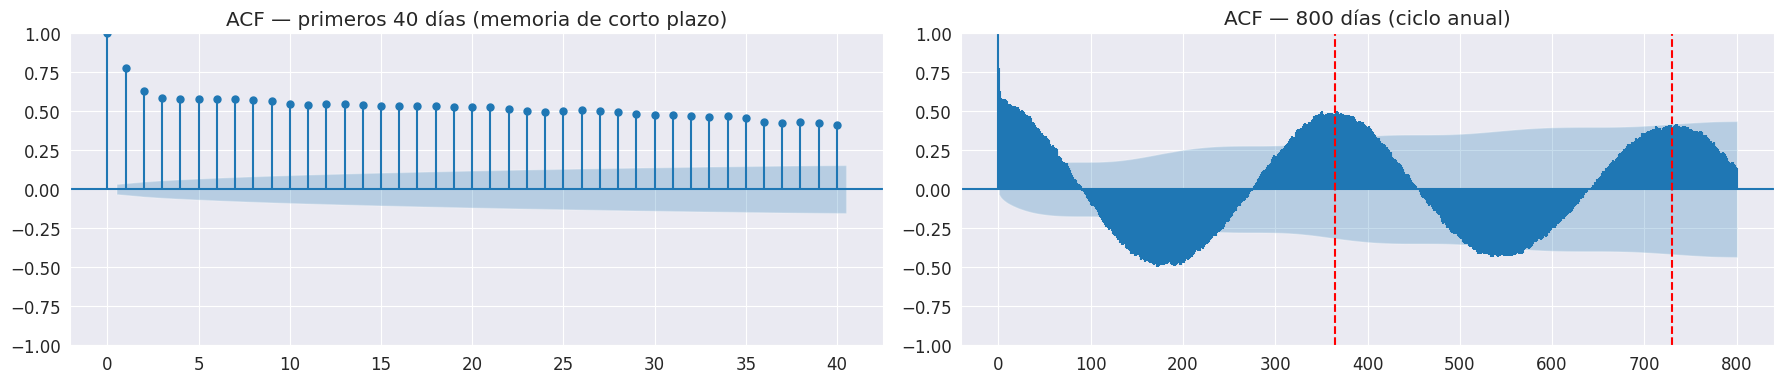

Varianza explicada por la estacionalidad anual: 57.8%
Varianza del residuo (ruido día a día):        39.0%


In [ ]:
# ============================================================
# 📊 Descomposición (periodo anual = 365 días) y autocorrelación
# ============================================================
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

dec = seasonal_decompose(temp, model='additive', period=365)
fig, axes = plt.subplots(4, 1, figsize=(16, 11), sharex=True)
for ax, (name, data, c) in zip(axes, [('Original', temp, COLORS['actual']),
                                      ('Tendencia', dec.trend, COLORS['lstm']),
                                      ('Estacionalidad anual', dec.seasonal, COLORS['gru']),
                                      ('Residuo', dec.resid, '#F44336')]):
    ax.plot(data, color=c, lw=0.8); ax.set_ylabel(name)
axes[-1].set_xlabel('Días desde 1981-01-01')
fig.suptitle('Descomposición: x_t = T_t + S_t + R_t', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 4))
plot_acf(temp, lags=40, ax=axes[0]);  axes[0].set_title('ACF — primeros 40 días (memoria de corto plazo)')
plot_acf(temp, lags=800, ax=axes[1], marker=None); axes[1].set_title('ACF — 800 días (ciclo anual)')
axes[1].axvline(365, color='red', ls='--'); axes[1].axvline(730, color='red', ls='--')
plt.tight_layout(); plt.show()

print(f'Varianza explicada por la estacionalidad anual: '
      f'{np.nanvar(dec.seasonal) / np.nanvar(temp) * 100:.1f}%')
print(f'Varianza del residuo (ruido día a día):        '
      f'{np.nanvar(dec.resid) / np.nanvar(temp) * 100:.1f}%')

> 📝 **Interpretación:**
> - La **estacionalidad anual explica el 57.8%** de la varianza, y el **residuo (ruido día a día) el 39.0%**. Es decir, casi 4 de cada 10 partes de la variación son cambios bruscos del clima (frentes fríos, días de calor) que no siguen un patrón.
> - **ACF de corto plazo:** la correlación con el día anterior es **≈0.78** y baja a **≈0.58** al tercer día. Después decae muy lentamente, porque lo que queda es el efecto del ciclo anual. La información útil de "memoria reciente" se concentra en los primeros días.
> - **ACF de largo plazo:** hay picos positivos en **365 y 730 días (≈0.5 y ≈0.4)** y mínimos cerca de los 180 días (≈−0.5), lo que confirma el ciclo anual.

---
### 1.3 · Preprocesamiento: las 3 reglas de oro
1. **Split cronológico 80/20:** 1981–1988 para train y 1989–1990 para test.
2. **MinMaxScaler con `fit` solo en train.**
3. **Ventana de 30 días:** un mes de historia para predecir el día siguiente. Más adelante probamos 7, 30, 90 y 365 días.

> Para el test anteponemos los últimos `WINDOW` días del train. Así la primera predicción del test usa historia real y se evalúan **todos** los días del test.

Train: 2,921 días (1981-01-01 → 1988-12-30)
Test:  731 días (1988-12-31 → 1990-12-31)
X_train: (2891, 30, 1) (muestras, pasos, features) | y_train: (2891,)
X_test:  (731, 30, 1) | y_test: (731,)


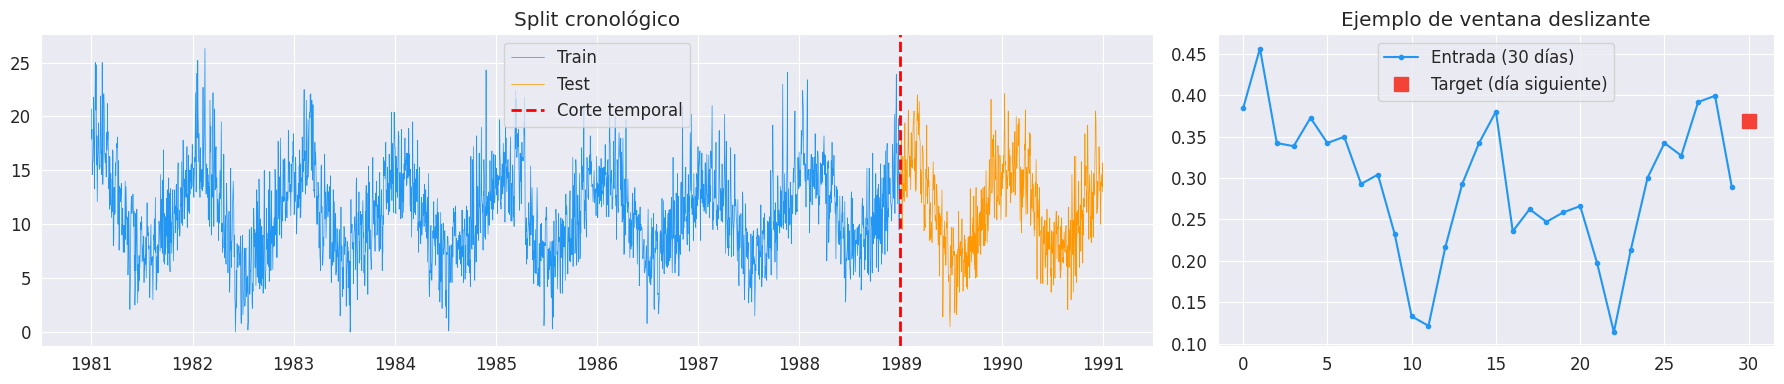

In [ ]:
# ============================================================
# 🔧 Split, normalización y ventanas
# ============================================================
split = int(len(temp) * 0.8)
train, test = temp[:split], temp[split:]

scaler = MinMaxScaler()
train_s = scaler.fit_transform(train.reshape(-1, 1)).flatten()
test_s  = scaler.transform(test.reshape(-1, 1)).flatten()
inv = lambda v: scaler.inverse_transform(np.asarray(v).reshape(-1, 1)).flatten()

WINDOW = 30
X_tr, y_tr = create_sequences(train_s, WINDOW)
X_te, y_te = create_sequences(np.concatenate([train_s[-WINDOW:], test_s]), WINDOW)

print(f'Train: {len(train):,} días ({df.index[0]:%Y-%m-%d} → {df.index[split-1]:%Y-%m-%d})')
print(f'Test:  {len(test):,} días ({df.index[split]:%Y-%m-%d} → {df.index[-1]:%Y-%m-%d})')
print(f'X_train: {X_tr.shape} (muestras, pasos, features) | y_train: {y_tr.shape}')
print(f'X_test:  {X_te.shape} | y_test: {y_te.shape}')

fig, axes = plt.subplots(1, 2, figsize=(18, 4), gridspec_kw={'width_ratios': [2, 1]})
axes[0].plot(df.index[:split], train, color=COLORS['lstm'], lw=0.5, label='Train')
axes[0].plot(df.index[split:], test, color=COLORS['gru'], lw=0.5, label='Test')
axes[0].axvline(df.index[split], color='red', ls='--', lw=2, label='Corte temporal')
axes[0].set_title('Split cronológico'); axes[0].legend()
axes[1].plot(range(WINDOW), X_tr[200, :, 0], 'o-', ms=3, color=COLORS['lstm'], label=f'Entrada ({WINDOW} días)')
axes[1].plot(WINDOW, y_tr[200], 's', ms=10, color='#F44336', label='Target (día siguiente)')
axes[1].set_title('Ejemplo de ventana deslizante'); axes[1].legend()
plt.tight_layout(); plt.show()

> 📝 **Interpretación:** el train tiene **2 921 días (01/01/1981 → 30/12/1988)** y el test **731 días (31/12/1988 → 31/12/1990)**, es decir, los dos últimos años completos. Con la ventana de 30 días se obtienen **2 891 secuencias de entrenamiento** de forma `(30, 1)` y **731 de test**, ya que al test se le antepusieron los últimos 30 días del train.

---
### 1.4 · Modelos LSTM y GRU

Ambos modelos tienen **exactamente la misma arquitectura**: 2 capas recurrentes apiladas (64 → 32), Dropout y una capa densa. Solo cambia el tipo de celda.

In [ ]:
# ============================================================
# 🏗️ Construcción de los modelos
# ============================================================
shape = (WINDOW, 1)
lstm = build_rnn('LSTM', shape, units=(64, 32), dropout=0.2, dense=16, name='LSTM_Melbourne')
gru  = build_rnn('GRU',  shape, units=(64, 32), dropout=0.2, dense=16, name='GRU_Melbourne')

lstm.summary()
gru.summary()
print(f'\n📊 Parámetros LSTM: {lstm.count_params():,} | GRU: {gru.count_params():,}')
print(f'   GRU es {(1 - gru.count_params()/lstm.count_params())*100:.1f}% más ligero')

Model: "LSTM_Melbourne"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_64_0 (LSTM)                │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_32_1 (LSTM)                │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Model: "GRU_Melbourne"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_64_0 (GRU)                  │ (None, 30, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_32_1 (GRU)                  │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,817 (89.13 KB)

 Trainable params: 22,817 (89.13 KB)

 Non-trainable params: 0 (0.00 B)


📊 Parámetros LSTM: 29,857 | GRU: 22,817
   GRU es 23.6% más ligero


🔵 Entrenando LSTM...
   ⏱️ 36.1s | épocas: 44 | mejor val_loss: 0.00868
🟠 Entrenando GRU...
   ⏱️ 14.1s | épocas: 17 | mejor val_loss: 0.00872

⚡ Relación de tiempo LSTM/GRU: 2.56x


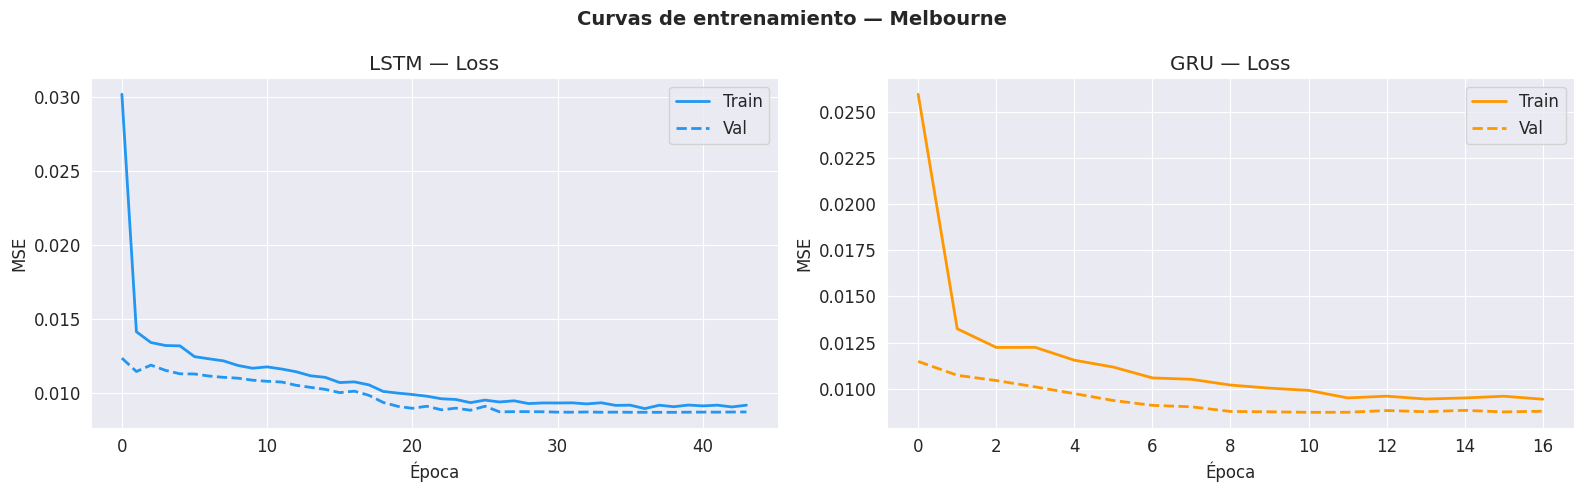

In [ ]:
# ============================================================
# 🚀 Entrenamiento
# ============================================================
print('🔵 Entrenando LSTM...')
hist_lstm, t_lstm = train_model(lstm, X_tr, y_tr, epochs=60, batch_size=32)
print(f'   ⏱️ {t_lstm:.1f}s | épocas: {len(hist_lstm.history["loss"])} | mejor val_loss: {min(hist_lstm.history["val_loss"]):.5f}')

print('🟠 Entrenando GRU...')
hist_gru, t_gru = train_model(gru, X_tr, y_tr, epochs=60, batch_size=32)
print(f'   ⏱️ {t_gru:.1f}s | épocas: {len(hist_gru.history["loss"])} | mejor val_loss: {min(hist_gru.history["val_loss"]):.5f}')
print(f'\n⚡ Relación de tiempo LSTM/GRU: {t_lstm/t_gru:.2f}x')

plot_histories({'LSTM': hist_lstm, 'GRU': hist_gru}, 'Curvas de entrenamiento — Melbourne')

> 📝 **Interpretación del entrenamiento:**
> - **Parámetros:** LSTM **29 857** vs GRU **22 817**. El GRU es **23.6% más ligero**, como predice la teoría (2 compuertas frente a 3).
> - **Convergencia:** ambos llegan prácticamente a la misma pérdida de validación (**0.00868 LSTM vs 0.00872 GRU**). El GRU lo logra en **17 épocas** y el LSTM necesita **44**.
> - **Tiempo:** el GRU terminó en **14.1 s** frente a **36.1 s** del LSTM (**2.56× más rápido**). Ojo: el tiempo **por época** fue casi igual (~0.82 s en ambos, porque la GPU usa cuDNN para las dos celdas). La ventaja del GRU vino de **converger en menos épocas**, no de que cada época sea más barata.
> - **Sobreajuste:** no hay. La curva de validación queda por debajo de la de entrenamiento durante todo el proceso, algo normal porque el Dropout solo actúa al entrenar.

---
### 1.5 · Evaluación contra baselines

| Baseline | Predicción para mañana |
|---|---|
| **Naive (t-1)** | La temperatura de hoy |
| **Naive estacional (t-365)** | La temperatura del mismo día del año anterior |
| **Media móvil 7 días** | El promedio de la última semana |

Un modelo de deep learning solo se justifica si **supera al mejor baseline**.

In [ ]:
# ============================================================
# 📏 Métricas en °C
# ============================================================
y_real  = inv(y_te)
p_lstm  = inv(lstm.predict(X_te, verbose=0))
p_gru   = inv(gru.predict(X_te, verbose=0))
p_naive = inv(X_te[:, -1, 0])
p_ma7   = inv(X_te[:, -7:, 0].mean(axis=1))
p_snaive = temp[split - 365: len(temp) - 365]          # mismo día, año anterior

res = {
    'Naive (t-1)':          evaluate_forecast(y_real, p_naive),
    'Naive estac. (t-365)': evaluate_forecast(y_real, p_snaive),
    'Media móvil 7 días':   evaluate_forecast(y_real, p_ma7),
    'LSTM':                 {**evaluate_forecast(y_real, p_lstm), 'params': lstm.count_params(), 'time': t_lstm},
    'GRU':                  {**evaluate_forecast(y_real, p_gru),  'params': gru.count_params(),  'time': t_gru},
}
print('COMPARACIÓN — TEMPERATURA MÍNIMA DE MELBOURNE (°C)')
print_table(res, '(°C)')

mejor_base = min(res[k]['MAE'] for k in ['Naive (t-1)', 'Naive estac. (t-365)', 'Media móvil 7 días'])
for m in ['LSTM', 'GRU']:
    print(f'{m}: {(1 - res[m]["MAE"]/mejor_base)*100:+.1f}% de mejora en MAE respecto al mejor baseline')

COMPARACIÓN — TEMPERATURA MÍNIMA DE MELBOURNE (°C)
Modelo                 MAE (°C)      RMSE (°C)     R²       Params     Tiempo (s)
--------------------------------------------------------------------------------
Naive (t-1)            1.950         2.479         0.635    —          —         
Naive estac. (t-365)   2.954         3.738         0.170    —          —         
Media móvil 7 días     2.039         2.594         0.600    —          —         
LSTM                   1.746         2.226         0.706    29,857     36.1      
GRU                    1.750         2.231         0.704    22,817     14.1      
LSTM: +10.5% de mejora en MAE respecto al mejor baseline
GRU: +10.3% de mejora en MAE respecto al mejor baseline


> 📝 **Interpretación de las métricas:**
>
> | Modelo | MAE (°C) | R² | Lectura |
> |---|---|---|---|
> | Naive estacional (t-365) | 2.954 | 0.170 | El peor: el clima de un día concreto **no se repite** de un año a otro |
> | Media móvil 7 días | 2.039 | 0.600 | Suaviza demasiado y reacciona tarde |
> | Naive (t-1) | 1.950 | 0.635 | El mejor baseline: "mañana será como hoy" |
> | **LSTM** | **1.746** | **0.706** | **10.5% mejor** que el mejor baseline |
> | **GRU** | 1.750 | 0.704 | **10.3% mejor** que el mejor baseline |
>
> - Ambas redes **superan claramente a todos los baselines**. En promedio fallan por **~1.75 °C** y explican el **~70% de la varianza** de la temperatura.
> - La diferencia entre LSTM y GRU es de solo **0.004 °C** en MAE y **0.002** en R², un **empate técnico**: con otra semilla aleatoria el orden podría invertirse.
> - Considerando que el GRU usa 24% menos parámetros y entrenó 2.5× más rápido, **el GRU es la opción más eficiente** para este dataset.

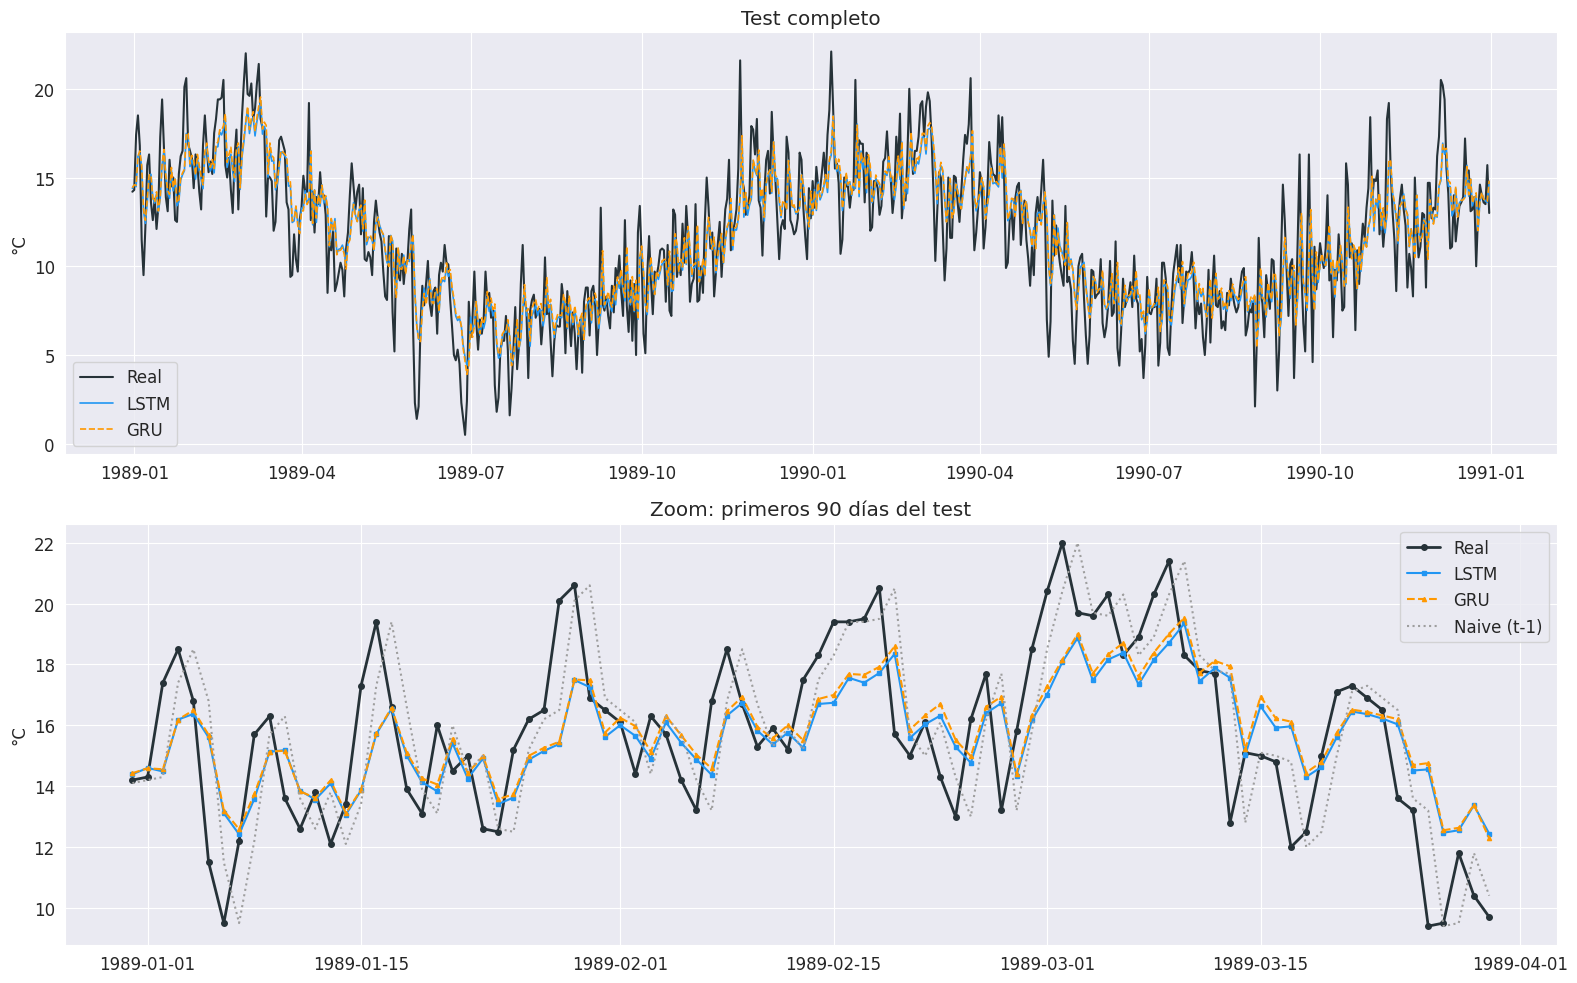

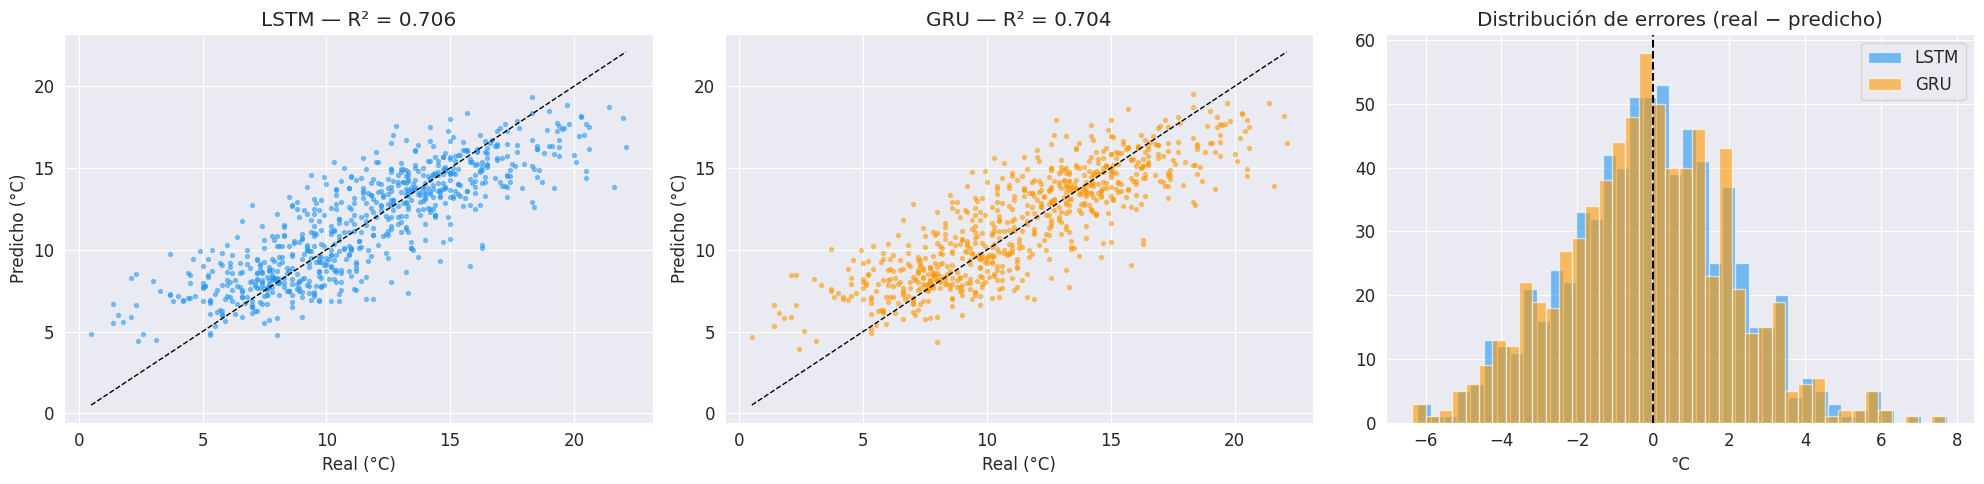

In [ ]:
# ============================================================
# 📊 Predicciones vs valores reales
# ============================================================
idx_test = df.index[split:]
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

axes[0].plot(idx_test, y_real, color=COLORS['actual'], lw=1.5, label='Real')
axes[0].plot(idx_test, p_lstm, color=COLORS['lstm'], lw=1.2, label='LSTM')
axes[0].plot(idx_test, p_gru, color=COLORS['gru'], lw=1.2, ls='--', label='GRU')
axes[0].set_title('Test completo'); axes[0].set_ylabel('°C'); axes[0].legend()

z = slice(0, 90)
axes[1].plot(idx_test[z], y_real[z], 'o-', color=COLORS['actual'], ms=4, lw=2, label='Real')
axes[1].plot(idx_test[z], p_lstm[z], 's-', color=COLORS['lstm'], ms=3, label='LSTM')
axes[1].plot(idx_test[z], p_gru[z], '^--', color=COLORS['gru'], ms=3, label='GRU')
axes[1].plot(idx_test[z], p_naive[z], ':', color=COLORS['naive'], label='Naive (t-1)')
axes[1].set_title('Zoom: primeros 90 días del test'); axes[1].set_ylabel('°C'); axes[1].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (n, p) in zip(axes[:2], [('LSTM', p_lstm), ('GRU', p_gru)]):
    ax.scatter(y_real, p, s=8, alpha=0.5, color=COLORS[n.lower()])
    lim = [min(y_real.min(), p.min()), max(y_real.max(), p.max())]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_title(f'{n} — R² = {res[n]["R2"]:.3f}'); ax.set_xlabel('Real (°C)'); ax.set_ylabel('Predicho (°C)')
axes[2].hist(y_real - p_lstm, bins=40, alpha=0.6, color=COLORS['lstm'], label='LSTM')
axes[2].hist(y_real - p_gru, bins=40, alpha=0.6, color=COLORS['gru'], label='GRU')
axes[2].axvline(0, color='k', ls='--'); axes[2].set_title('Distribución de errores (real − predicho)')
axes[2].set_xlabel('°C'); axes[2].legend()
plt.tight_layout(); plt.show()

> 📝 **Interpretación de los gráficos:**
> - **Test completo:** ambos modelos siguen bien el ciclo estacional de 1989 y 1990. Las curvas de LSTM y GRU casi se superponen.
> - **Extremos:** los modelos **suavizan los extremos**. No alcanzan las caídas bruscas del invierno de 1989 (días cercanos a 0–2 °C, cuando el modelo predice ~4–6 °C) ni los picos de calor de más de 20 °C. Es el efecto típico de entrenar con MSE: el modelo prefiere predecir valores "seguros" cerca de la media local.
> - **Zoom de 90 días:** las predicciones se parecen a una versión **suavizada y algo retrasada** del naive. Cuando hay un salto brusco, el modelo lo "ve" recién al día siguiente. Es la limitación de usar **solo la temperatura**: sin presión, viento o nubosidad no hay forma de anticipar un frente frío.
> - **Dispersión y errores:** los puntos se agrupan alrededor de la diagonal (R² ≈ 0.70) y los errores están **centrados en 0**, sin sesgo sistemático.

---
### 1.6 · Experimento: tamaño de ventana

¿Cuánta historia necesitan LSTM y GRU? Probamos 7 días (1 semana), 30 (1 mes), 90 (1 estación) y 365 (1 año).

  ventana=  7 días | LSTM | MAE=1.779°C | 21.0s | muestras train=2,914
  ventana=  7 días | GRU  | MAE=1.789°C | 12.4s | muestras train=2,914
  ventana= 30 días | LSTM | MAE=1.747°C | 30.4s | muestras train=2,891
  ventana= 30 días | GRU  | MAE=1.738°C | 14.0s | muestras train=2,891
  ventana= 90 días | LSTM | MAE=1.968°C | 25.9s | muestras train=2,831
  ventana= 90 días | GRU  | MAE=1.747°C | 28.3s | muestras train=2,831
  ventana=365 días | LSTM | MAE=1.964°C | 63.7s | muestras train=2,556
  ventana=365 días | GRU  | MAE=1.745°C | 34.8s | muestras train=2,556


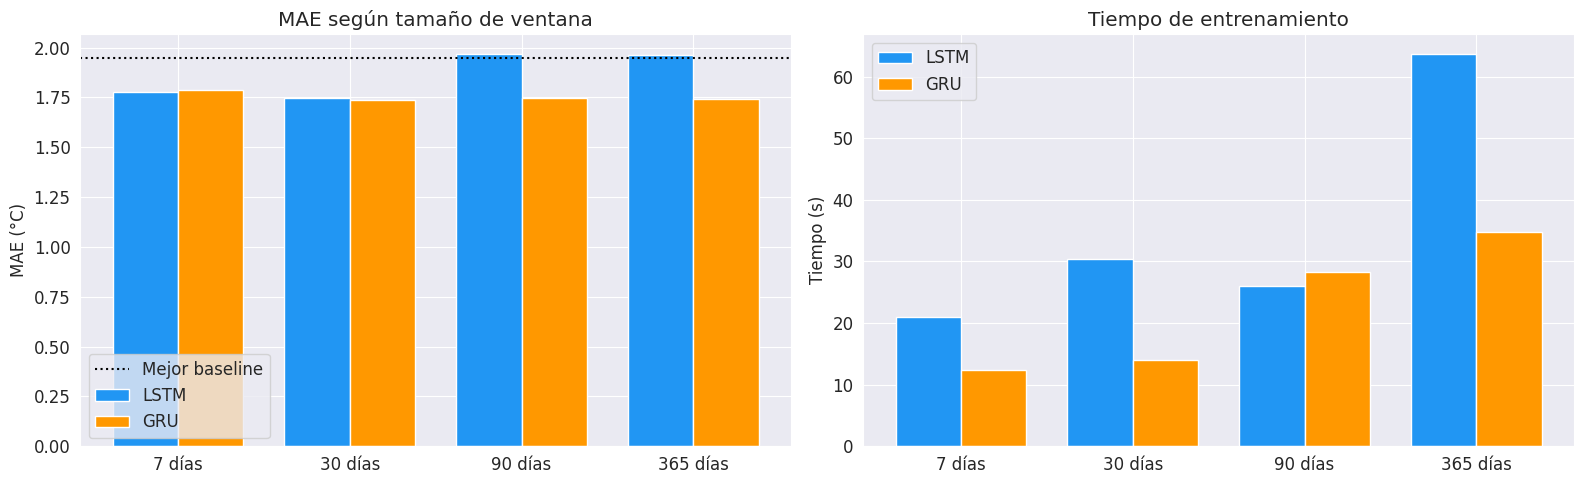

In [ ]:
# ============================================================
# 🔍 Experimento de ventana — LSTM vs GRU
# ============================================================
windows = [7, 30, 90, 365]
exp = {'LSTM': {'MAE': [], 'time': []}, 'GRU': {'MAE': [], 'time': []}}

for w in windows:
    Xtr, ytr = create_sequences(train_s, w)
    Xte, yte = create_sequences(np.concatenate([train_s[-w:], test_s]), w)
    for cell in ['LSTM', 'GRU']:
        m = build_rnn(cell, (w, 1), units=(64, 32), dropout=0.2, dense=16)
        _, t = train_model(m, Xtr, ytr, epochs=40, batch_size=32)
        mae = mean_absolute_error(inv(yte), inv(m.predict(Xte, verbose=0)))
        exp[cell]['MAE'].append(mae); exp[cell]['time'].append(t)
        print(f'  ventana={w:>3} días | {cell:<4} | MAE={mae:.3f}°C | {t:.1f}s | muestras train={len(Xtr):,}')

x = np.arange(len(windows)); wb = 0.38
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for k, ax, lab in [('MAE', axes[0], 'MAE (°C)'), ('time', axes[1], 'Tiempo (s)')]:
    ax.bar(x - wb/2, exp['LSTM'][k], wb, color=COLORS['lstm'], label='LSTM')
    ax.bar(x + wb/2, exp['GRU'][k],  wb, color=COLORS['gru'],  label='GRU')
    ax.set_xticks(x); ax.set_xticklabels([f'{w} días' for w in windows]); ax.set_ylabel(lab); ax.legend()
axes[0].axhline(mejor_base, color='k', ls=':', label='Mejor baseline'); axes[0].legend()
axes[0].set_title('MAE según tamaño de ventana'); axes[1].set_title('Tiempo de entrenamiento')
plt.tight_layout(); plt.show()

> 📝 **Interpretación del experimento de ventana:**
>
> | Ventana | LSTM MAE | GRU MAE | LSTM tiempo | GRU tiempo |
> |---|---|---|---|---|
> | 7 días | 1.779 | 1.789 | 21.0 s | 12.4 s |
> | **30 días** | **1.747** | **1.738** | 30.4 s | 14.0 s |
> | 90 días | 1.968 | 1.747 | 25.9 s | 28.3 s |
> | 365 días | 1.964 | 1.745 | 63.7 s | 34.8 s |
>
> - **La mejor ventana para ambos es 30 días.** Con solo 7 días el error ya es casi igual (+0.03–0.05 °C). Esto coincide con la ACF: la información útil está en los últimos días.
> - **El GRU es muy estable:** su MAE apenas cambia entre 30 y 365 días (1.738 → 1.745).
> - **El LSTM empeora con ventanas largas** (≈1.97 °C con 90 y 365 días). Con secuencias más largas y menos muestras (2 556 con la ventana de 365) le cuesta más optimizar sus tres compuertas y se detuvo en una solución peor. El GRU, más simple, es más robusto en este caso.
> - **Costo:** la ventana de 365 días cuadruplica el tiempo del LSTM (63.7 s) sin ninguna ganancia de precisión.

---
## 🏁 Resumen

In [ ]:
# ============================================================
# 📋 Resumen final
# ============================================================
resumen = pd.DataFrame(res).T[['MAE', 'RMSE', 'R2']].astype(float).round(3)
resumen['Parámetros'] = [res[k].get('params', '—') for k in res]
resumen['Tiempo (s)'] = [round(res[k]['time'], 1) if res[k].get('time') else '—' for k in res]
display(resumen)

ganador = 'LSTM' if res['LSTM']['MAE'] < res['GRU']['MAE'] else 'GRU'
dif = abs(res['LSTM']['MAE'] - res['GRU']['MAE'])
print(f'• Menor MAE: {ganador} (diferencia de {dif:.3f}°C entre ambos)')
print(f'• GRU usa {(1 - gru.count_params()/lstm.count_params())*100:.0f}% menos parámetros '
      f'y tardó {t_gru:.1f}s frente a {t_lstm:.1f}s del LSTM')
best_w = {c: windows[int(np.argmin(exp[c]['MAE']))] for c in exp}
print(f'• Mejor ventana: LSTM → {best_w["LSTM"]} días | GRU → {best_w["GRU"]} días')

,MAE,RMSE,R2,Parámetros,Tiempo (s)
Naive (t-1),1.950,2.479,0.635,—,—
Naive estac. (t-365),2.954,3.738,0.170,—,—
Media móvil 7 días,2.039,2.594,0.600,—,—
LSTM,1.746,2.226,0.706,29857,36.1
GRU,1.750,2.231,0.704,22817,14.1


• Menor MAE: LSTM (diferencia de 0.004°C entre ambos)
• GRU usa 24% menos parámetros y tardó 14.1s frente a 36.1s del LSTM
• Mejor ventana: LSTM → 30 días | GRU → 30 días


In [ ]:
# Guardamos los resultados de la Parte 1 para la comparación final
# (la Parte 2 reutiliza los nombres res, lstm, gru, etc.)
res_melb = dict(res)
exp_melb = {'windows': windows, **exp}
print('✅ Resultados de la Parte 1 guardados en res_melb')

### 💡 Conclusiones de la Parte 1
1. **Baselines:** el naive (t-1) es el rival más fuerte (MAE 1.950 °C), porque la temperatura de hoy se parece mucho a la de ayer (autocorrelación ≈0.78). El naive estacional es el peor (2.954 °C): la estacionalidad anual existe, pero el clima de una fecha concreta varía mucho entre años. **LSTM y GRU mejoran el MAE en ~10.5%** sobre el mejor baseline y elevan el R² de 0.635 a ~0.705.
2. **LSTM vs GRU:** empate en precisión (1.746 vs 1.750 °C), pero el **GRU usa 23.6% menos parámetros y entrenó 2.56× más rápido** al converger en menos épocas. Para este problema se cumple la regla de clase: **"empieza con GRU"**.
3. **Ventana:** **30 días** es el mejor equilibrio. Usar un año de historia no mejora la precisión, encarece el entrenamiento y, en el caso del LSTM, empeora el resultado (≈1.97 °C).
4. **Límite del modelo:** el ~39% de la varianza es ruido día a día que la temperatura sola no puede anticipar. Por eso los modelos suavizan los extremos y reaccionan con un día de retraso a los cambios bruscos. Para mejorar habría que **agregar más variables**, que es justamente el enfoque multivariado de la Parte 2.

#### ✅ Checklist Parte 1
| # | Verificación | Estado |
|---|---|---|
| 1 | Limpieza: línea de texto final, valores no numéricos y 2 días faltantes | ✅ |
| 2 | Split cronológico 80/20 (1981–1988 / 1989–1990) | ✅ |
| 3 | `MinMaxScaler` ajustado solo en train | ✅ |
| 4 | Shapes `(samples, timesteps, features)` = `(2891, 30, 1)` | ✅ |
| 5 | Tres baselines antes de evaluar los modelos | ✅ |
| 6 | Misma arquitectura para LSTM y GRU | ✅ |
| 7 | EarlyStopping + ReduceLROnPlateau | ✅ |
| 8 | Métricas desnormalizadas (°C) | ✅ |

---
# ⚡ PARTE 2: Consumo energético de electrodomésticos (multivariado)

**Dataset:** [Appliances Energy Prediction](https://www.kaggle.com/datasets/loveall/appliances-energy-prediction) (Kaggle; original en UCI, Candanedo et al., 2017).
- Una casa de bajo consumo en Bélgica, medida **cada 10 minutos** durante ~4.5 meses (enero–mayo de 2016), con **19 735 registros**.
- **Target:** `Appliances`, el consumo de los electrodomésticos en Wh.
- **Variables:** temperatura (`T1`–`T9`) y humedad (`RH_1`–`RH_9`) de 9 ambientes, consumo de luces (`lights`) y clima exterior (`T_out`, `Press_mm_hg`, `RH_out`, `Windspeed`, `Visibility`, `Tdewpoint`).
- `rv1` y `rv2` son **variables aleatorias** que los autores agregaron a propósito para probar métodos de selección de variables. Se eliminan.

**Tarea:** Forecasting multivariado many-to-one. Con las **últimas 24 horas** (144 pasos de 10 min) de las 30 variables, se predice el consumo **1 hora adelante**.

---
### 2.1 · Carga del dataset desde Kaggle

Igual que en la Parte 1, descargamos la carpeta con `kagglehub.dataset_download` y buscamos el CSV dentro. Así no hace falta conocer de antemano el nombre exacto del archivo, que es lo que pedía `file_path` en `load_dataset`.

> Si Kaggle pide autenticación: Colab → 🔑 *Secrets* → `KAGGLE_USERNAME` y `KAGGLE_KEY`.

In [4]:
# ============================================================
# 📥 Descarga desde Kaggle
# ============================================================
path = kagglehub.dataset_download('loveall/appliances-energy-prediction')
csvs = sorted(glob.glob(os.path.join(path, '**', '*.csv'), recursive=True))
print('Archivos encontrados:', [os.path.basename(c) for c in csvs])

df_raw = pd.read_csv(csvs[0])
print(f'Shape: {df_raw.shape}')
print('Columnas:', list(df_raw.columns))
print('First 5 records:')
df_raw.head()

100%|██████████| 1.71M/1.71M [00:01<00:00, 1.43MB/s]

Extracting files...


Archivos encontrados: ['KAG_energydata_complete.csv']
Shape: (19735, 29)
Columnas: ['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']
First 5 records:


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [5]:
# ============================================================
# 🧹 Índice temporal y verificación de frecuencia
# ============================================================
df = df_raw.copy()
col_fecha = [c for c in df.columns if c.lower() == 'date'][0]
df[col_fecha] = pd.to_datetime(df[col_fecha])
df = df.set_index(col_fecha).sort_index()
df = df[~df.index.duplicated()]
df = df.drop(columns=[c for c in ['rv1', 'rv2'] if c in df.columns])   # variables aleatorias

pasos = df.index.to_series().diff().value_counts()
print('Intervalos entre registros:\n', pasos.head())

# Asegurar una grilla regular de 10 minutos (rellenar huecos si existieran)
full_idx = pd.date_range(df.index.min(), df.index.max(), freq='10min')
huecos = len(full_idx) - len(df)
df = df.reindex(full_idx).interpolate().ffill().bfill()
print(f'\nHuecos rellenados: {huecos}')
print(f'Serie final: {df.shape[0]:,} registros × {df.shape[1]} variables')
print(f'Rango: {df.index.min()} → {df.index.max()}')
print(f'Valores nulos restantes: {df.isna().sum().sum()}')
df.describe().T.round(2)

Intervalos entre registros:
 date
0 days 00:10:00    19734
Name: count, dtype: int64

Huecos rellenados: 0
Serie final: 19,735 registros × 26 variables
Rango: 2016-01-11 17:00:00 → 2016-05-27 18:00:00
Valores nulos restantes: 0


,count,mean,std,min,25%,50%,75%,max
Appliances,19735.0,97.69,102.52,10.00,50.00,60.00,100.00,1080.00
lights,19735.0,3.80,7.94,0.00,0.00,0.00,0.00,70.00
T1,19735.0,21.69,1.61,16.79,20.76,21.60,22.60,26.26
RH_1,19735.0,40.26,3.98,27.02,37.33,39.66,43.07,63.36
T2,19735.0,20.34,2.19,16.10,18.79,20.00,21.50,29.86
RH_2,19735.0,40.42,4.07,20.46,37.90,40.50,43.26,56.03
T3,19735.0,22.27,2.01,17.20,20.79,22.10,23.29,29.24
RH_3,19735.0,39.24,3.25,28.77,36.90,38.53,41.76,50.16
T4,19735.0,20.86,2.04,15.10,19.53,20.67,22.10,26.20
RH_4,19735.0,39.03,4.34,27.66,35.53,38.40,42.16,51.09


> 📝 **Interpretación:** el dataset tiene **19 735 registros × 29 columnas**, todos separados exactamente **10 minutos**, sin huecos ni valores nulos (del 11/01/2016 17:00 al 27/05/2016 18:00). Tras eliminar `rv1` y `rv2` quedan **26 variables**. El consumo `Appliances` tiene una **media de 97.7 Wh** pero una **mediana de solo 60 Wh** y un **máximo de 1 080 Wh**: la media está "inflada" por unos pocos picos muy altos.

---
### 2.2 · Exploración

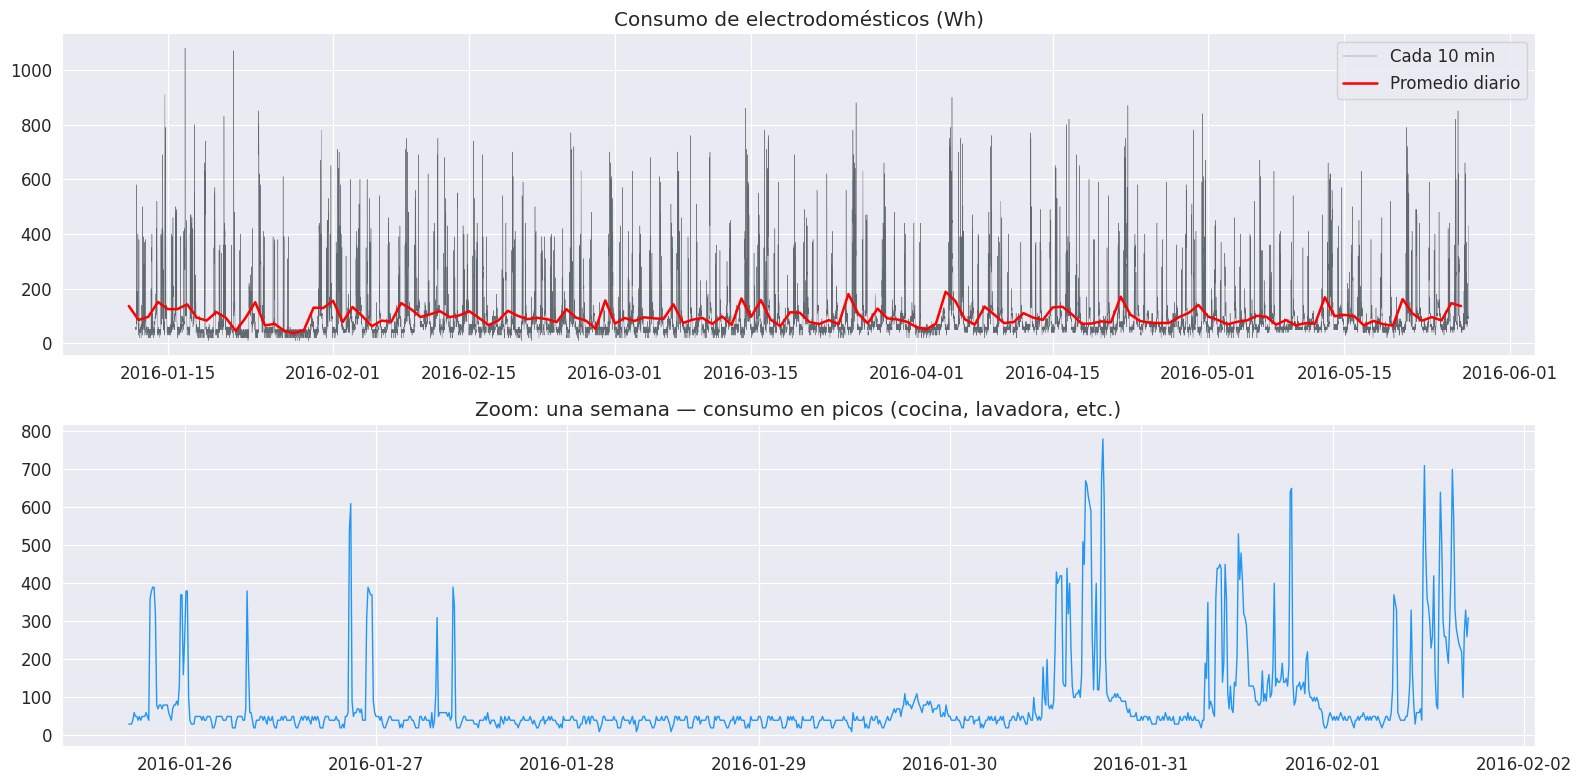

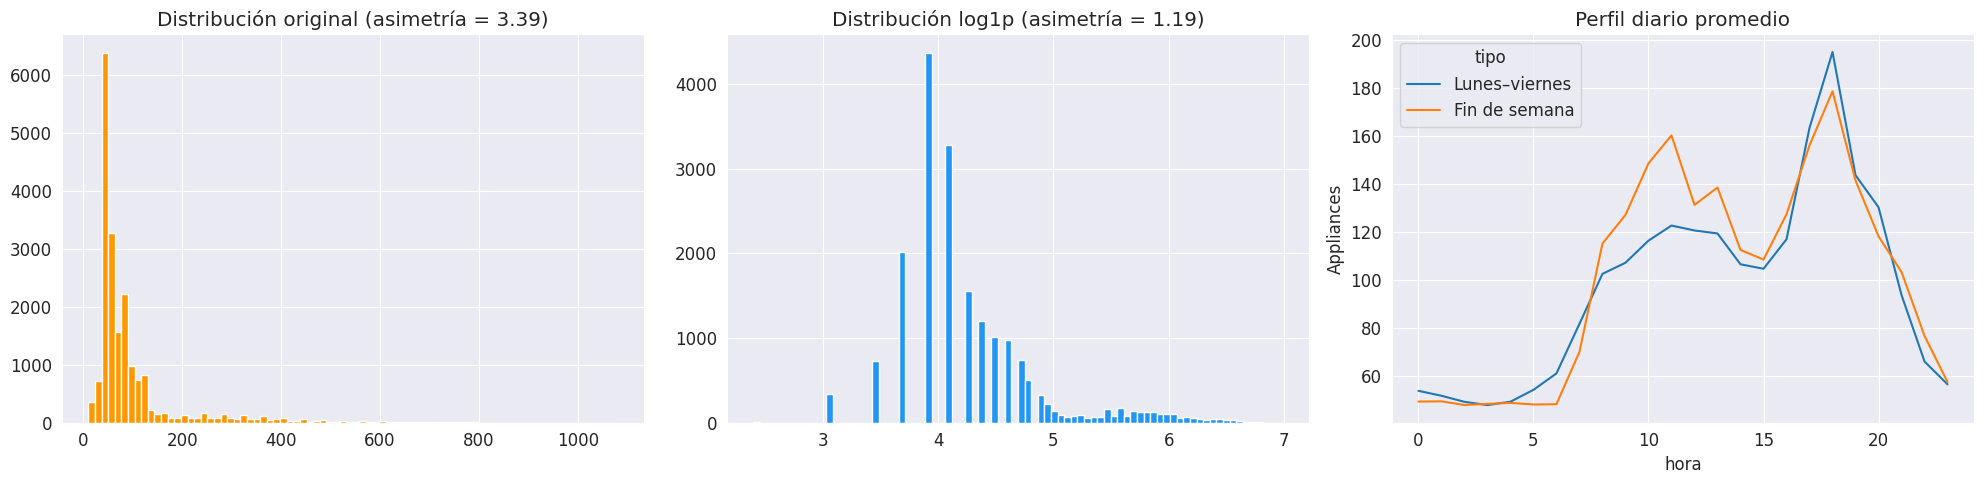

In [6]:
# ============================================================
# 📈 El target: consumo de electrodomésticos
# ============================================================
TARGET = 'Appliances'
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
axes[0].plot(df.index, df[TARGET], color=COLORS['actual'], lw=0.3, alpha=0.7, label='Cada 10 min')
axes[0].plot(df[TARGET].resample('D').mean(), color='red', lw=1.8, label='Promedio diario')
axes[0].set_title('Consumo de electrodomésticos (Wh)'); axes[0].legend()
semana = df.loc[df.index[0] + pd.Timedelta(days=14): df.index[0] + pd.Timedelta(days=21), TARGET]
axes[1].plot(semana.index, semana, color=COLORS['lstm'], lw=1)
axes[1].set_title('Zoom: una semana — consumo en picos (cocina, lavadora, etc.)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].hist(df[TARGET], bins=80, color=COLORS['gru'])
axes[0].set_title(f'Distribución original (asimetría = {df[TARGET].skew():.2f})')
axes[1].hist(np.log1p(df[TARGET]), bins=80, color=COLORS['lstm'])
axes[1].set_title(f'Distribución log1p (asimetría = {np.log1p(df[TARGET]).skew():.2f})')
perfil = df.assign(hora=df.index.hour,
                   tipo=np.where(df.index.dayofweek < 5, 'Lunes–viernes', 'Fin de semana'))
sns.lineplot(data=perfil, x='hora', y=TARGET, hue='tipo', ax=axes[2], errorbar=None)
axes[2].set_title('Perfil diario promedio')
plt.tight_layout(); plt.show()

> 📌 **Observación clave:** el consumo es **muy asimétrico**. La mayor parte del tiempo está entre 50 y 100 Wh, con picos de hasta ~1 000 Wh. Con MSE, unos pocos picos dominarían el entrenamiento. Por eso entrenamos sobre **log(1 + Appliances)** y luego invertimos con `expm1` para reportar las métricas en Wh.

> 📝 **Interpretación:**
> - **Asimetría:** la distribución original tiene una asimetría de **3.39**. Con `log1p` baja a **1.19**, mucho más manejable para entrenar con MSE.
> - **Patrón semanal:** la serie muestra un **consumo base de ~50–60 Wh** interrumpido por picos cortos de 300–600 Wh (cocina, lavadora, horno).
> - **Perfil diario:** de madrugada (0–6 h) el consumo es mínimo (~50 Wh). El **pico principal es a las 18 h** (~195 Wh entre semana y ~178 Wh el fin de semana). Los fines de semana hay además un pico matutino más alto, cerca de las 11 h (~160 Wh frente a ~123 Wh entre semana), porque la familia está en casa. La **hora del día y el tipo de día** importan, y por eso se codifican como variables.

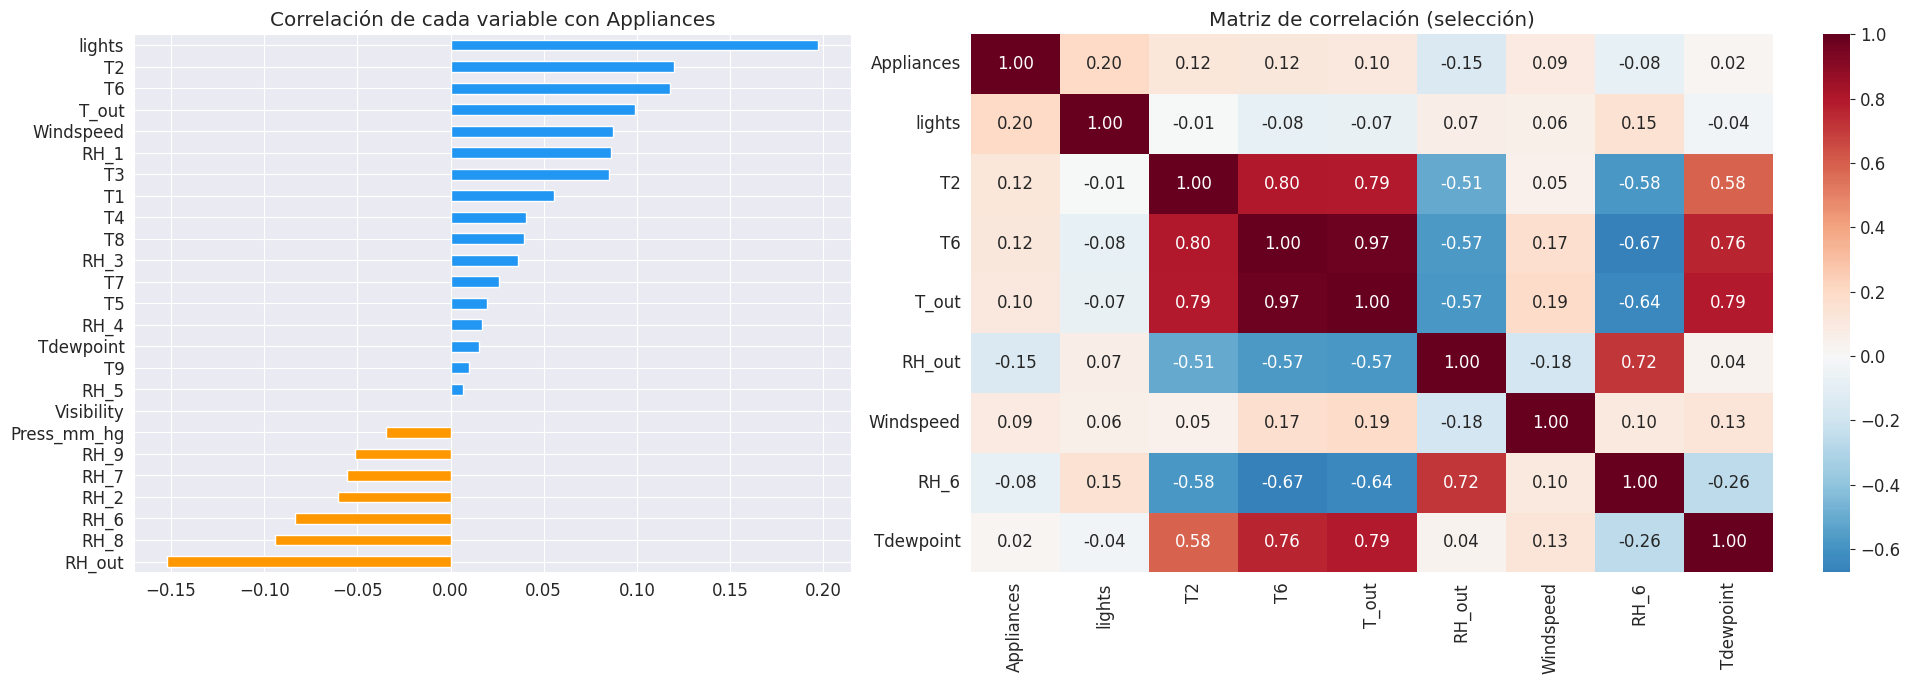

Las correlaciones lineales son bajas (|r| < 0.3). Las RNN pueden captar relaciones
no lineales y temporales que la correlación simple no muestra.


In [7]:
# ============================================================
# 🔗 Correlaciones con el target
# ============================================================
corr = df.corr()[TARGET].drop(TARGET).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={'width_ratios': [1, 1.4]})
corr.plot(kind='barh', ax=axes[0], color=[COLORS['lstm'] if v > 0 else COLORS['gru'] for v in corr])
axes[0].set_title('Correlación de cada variable con Appliances')
grupo = ['Appliances', 'lights', 'T2', 'T6', 'T_out', 'RH_out', 'Windspeed', 'RH_6', 'Tdewpoint']
grupo = [g for g in grupo if g in df.columns]
sns.heatmap(df[grupo].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('Matriz de correlación (selección)')
plt.tight_layout(); plt.show()
print('Las correlaciones lineales son bajas (|r| < 0.3). Las RNN pueden captar relaciones')
print('no lineales y temporales que la correlación simple no muestra.')

> 📝 **Interpretación:**
> - Todas las correlaciones lineales con el consumo son **débiles**. Las más altas son `lights` (**+0.20**), `RH_out` (**−0.15**), `T2` y `T6` (**+0.12**) y `T_out` (**+0.10**). Ninguna variable por sí sola explica el consumo.
> - Hay **mucha redundancia** entre variables: `T6` (sensor exterior, lado norte) y `T_out` tienen r = **0.97**, y `T2`–`T6` r = **0.80**. Varias columnas aportan casi la misma información, lo que puede introducir ruido en el modelo.

---
### 2.3 · Ingeniería de variables
- **Target transformado:** `log1p(Appliances)` en la columna 0.
- **Calendario cíclico:** la hora del día y el día de la semana se codifican con seno y coseno, para que la red sepa que las 23:50 están "al lado" de las 00:00.
- Se mantienen las 24 variables ambientales originales.

In [8]:
# ============================================================
# 🧩 Matriz de variables
# ============================================================
feat = df.copy()
feat[TARGET] = np.log1p(feat[TARGET])
minutos = feat.index.hour * 60 + feat.index.minute
feat['hr_sin'], feat['hr_cos'] = np.sin(2*np.pi*minutos/1440), np.cos(2*np.pi*minutos/1440)
feat['wd_sin'], feat['wd_cos'] = np.sin(2*np.pi*feat.index.dayofweek/7), np.cos(2*np.pi*feat.index.dayofweek/7)

FEATURES = [TARGET] + [c for c in feat.columns if c != TARGET]   # target SIEMPRE en la columna 0
feat = feat[FEATURES].astype('float32')
print(f'{len(FEATURES)} variables de entrada:')
print(FEATURES)

30 variables de entrada:
['Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'hr_sin', 'hr_cos', 'wd_sin', 'wd_cos']


---
### 2.4 · Preprocesamiento: split, normalización y ventanas
1. **Split cronológico 70/15/15** (train / validación / test). La validación es explícita y también cronológica.
2. **MinMaxScaler con `fit` solo en train**, aplicado a todas las variables.
3. **Ventana de 144 pasos (24 h)** para predecir el consumo **6 pasos adelante (1 h)**.

In [9]:
# ============================================================
# 🔧 Split, normalización y ventanas
# ============================================================
data = feat.values
n = len(data)
i_val, i_test = int(n * 0.70), int(n * 0.85)
train, val, test = data[:i_val], data[i_val:i_test], data[i_test:]

scaler = MinMaxScaler()
train_s = scaler.fit_transform(train)
val_s   = scaler.transform(val)
test_s  = scaler.transform(test)

WINDOW = 144     # 24 horas
AHEAD  = 6       # 1 hora adelante
X_tr, y_tr = create_sequences_ahead(train_s, WINDOW, AHEAD)
X_va, y_va = create_sequences_ahead(np.vstack([train_s[-(WINDOW + AHEAD - 1):], val_s]), WINDOW, AHEAD)
X_te, y_te = create_sequences_ahead(np.vstack([val_s[-(WINDOW + AHEAD - 1):], test_s]), WINDOW, AHEAD)

# Desnormalizar el target: escala MinMax → log1p → Wh
t_min, t_max = scaler.data_min_[0], scaler.data_max_[0]
inv_wh = lambda v: np.expm1(np.asarray(v).flatten() * (t_max - t_min) + t_min)

print(f'Train: {feat.index[0]:%Y-%m-%d} → {feat.index[i_val-1]:%Y-%m-%d}')
print(f'Val:   {feat.index[i_val]:%Y-%m-%d} → {feat.index[i_test-1]:%Y-%m-%d}')
print(f'Test:  {feat.index[i_test]:%Y-%m-%d} → {feat.index[-1]:%Y-%m-%d}')
print(f'X_train: {X_tr.shape}  (muestras, {WINDOW} pasos, {len(FEATURES)} variables)')
print(f'X_val:   {X_va.shape}')
print(f'X_test:  {X_te.shape}')
print(f'Memoria de X_train: {X_tr.nbytes / 1e6:.0f} MB')

Train: 2016-01-11 → 2016-04-16
Val:   2016-04-16 → 2016-05-07
Test:  2016-05-07 → 2016-05-27
X_train: (13665, 144, 30)  (muestras, 144 pasos, 30 variables)
X_val:   (2960, 144, 30)
X_test:  (2961, 144, 30)
Memoria de X_train: 236 MB


> 📝 **Interpretación:** el split cronológico deja **train del 11/01 al 16/04** (invierno y comienzo de primavera), **validación del 16/04 al 07/05** y **test del 07/05 al 27/05** (finales de primavera). Se generan **13 665 secuencias de entrenamiento** de forma `(144, 30)`, que ocupan **236 MB** en memoria. El test cae en una época **más cálida** que la mayor parte del train, así que el modelo se evalúa en condiciones que vio poco al entrenar.

---
### 2.5 · Modelos LSTM y GRU apilados

Misma arquitectura para ambos: 128 → 64 unidades recurrentes, Dropout y una capa densa de 32.

In [10]:
# ============================================================
# 🏗️ Construcción de los modelos
# ============================================================
shape = (WINDOW, len(FEATURES))
lstm = build_rnn('LSTM', shape, units=(128, 64), dropout=0.2, dense=32, name='LSTM_Stacked_Energy')
gru  = build_rnn('GRU',  shape, units=(128, 64), dropout=0.2, dense=32, name='GRU_Stacked_Energy')
lstm.summary()
gru.summary()
print(f'\n📊 Parámetros LSTM: {lstm.count_params():,} | GRU: {gru.count_params():,}')
print(f'   GRU es {(1 - gru.count_params()/lstm.count_params())*100:.1f}% más ligero')

Model: "LSTM_Stacked_Energy"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_128_0 (LSTM)               │ (None, 144, 128)       │        81,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 144, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_64_1 (LSTM)                │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,929 (519.25 KB)

 Trainable params: 132,929 (519.25 KB)

 Non-trainable params: 0 (0.00 B)

Model: "GRU_Stacked_Energy"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_128_0 (GRU)                 │ (None, 144, 128)       │        61,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 144, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_64_1 (GRU)                  │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,801 (393.75 KB)

 Trainable params: 100,801 (393.75 KB)

 Non-trainable params: 0 (0.00 B)


📊 Parámetros LSTM: 132,929 | GRU: 100,801
   GRU es 24.2% más ligero


🔵 Entrenando LSTM apilado...
   ⏱️ 46.4s | épocas: 17 | mejor val_loss: 0.01064
🟠 Entrenando GRU apilado...
   ⏱️ 48.1s | épocas: 22 | mejor val_loss: 0.00986

⚡ Relación de tiempo LSTM/GRU: 0.96x


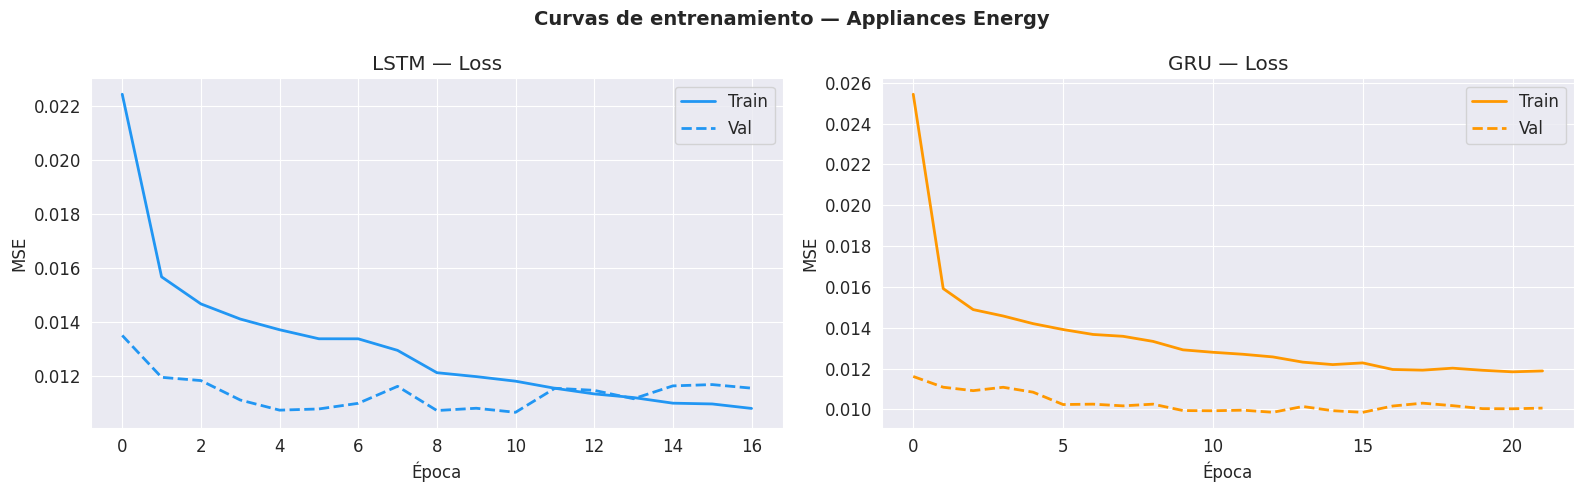

In [11]:
# ============================================================
# 🚀 Entrenamiento (validación explícita)
# ============================================================
print('🔵 Entrenando LSTM apilado...')
hist_lstm, t_lstm = train_model(lstm, X_tr, y_tr, val=(X_va, y_va), epochs=40, batch_size=128)
print(f'   ⏱️ {t_lstm:.1f}s | épocas: {len(hist_lstm.history["loss"])} | mejor val_loss: {min(hist_lstm.history["val_loss"]):.5f}')

print('🟠 Entrenando GRU apilado...')
hist_gru, t_gru = train_model(gru, X_tr, y_tr, val=(X_va, y_va), epochs=40, batch_size=128)
print(f'   ⏱️ {t_gru:.1f}s | épocas: {len(hist_gru.history["loss"])} | mejor val_loss: {min(hist_gru.history["val_loss"]):.5f}')
print(f'\n⚡ Relación de tiempo LSTM/GRU: {t_lstm/t_gru:.2f}x')

plot_histories({'LSTM': hist_lstm, 'GRU': hist_gru}, 'Curvas de entrenamiento — Appliances Energy')

> 📝 **Interpretación del entrenamiento:**
> - **Parámetros:** LSTM **132 929** vs GRU **100 801**. El GRU es **24.2% más ligero**.
> - **Validación:** el GRU alcanzó una mejor pérdida de validación (**0.00986 vs 0.01064**).
> - **Tiempo:** el total fue similar (46.4 s LSTM vs 48.1 s GRU), pero el GRU entrenó **22 épocas** y el LSTM **17**. **Por época, el GRU fue ~20% más rápido** (2.19 s vs 2.73 s).
> - **Sobreajuste:** en el LSTM, la pérdida de validación **empieza a subir después de la época ~10** mientras la de entrenamiento sigue bajando, una señal de sobreajuste. EarlyStopping restauró los mejores pesos. El GRU muestra una validación más estable y plana.

---
### 2.6 · Evaluación contra baselines

| Baseline | Predicción para dentro de 1 hora |
|---|---|
| **Naive (último valor)** | El consumo de los últimos 10 minutos |
| **Naive estacional (t-24h)** | El consumo de ayer a la misma hora |
| **Media de la última hora** | El promedio de los últimos 6 registros |

In [12]:
# ============================================================
# 📏 Métricas en Wh
# ============================================================
y_real   = inv_wh(y_te)
p_lstm   = inv_wh(lstm.predict(X_te, verbose=0))
p_gru    = inv_wh(gru.predict(X_te, verbose=0))
p_naive  = inv_wh(X_te[:, -1, 0])
p_snaive = inv_wh(X_te[:, AHEAD - 1, 0])        # exactamente 144 pasos (24 h) antes del target
p_mean1h = inv_wh(X_te[:, -6:, 0]).reshape(-1, 6).mean(axis=1)

res = {
    'Naive (último valor)':  evaluate_forecast(y_real, p_naive),
    'Naive estac. (t-24h)':  evaluate_forecast(y_real, p_snaive),
    'Media última hora':     evaluate_forecast(y_real, p_mean1h),
    'LSTM apilado':          {**evaluate_forecast(y_real, p_lstm), 'params': lstm.count_params(), 'time': t_lstm},
    'GRU apilado':           {**evaluate_forecast(y_real, p_gru),  'params': gru.count_params(),  'time': t_gru},
}
print('COMPARACIÓN — CONSUMO DE ELECTRODOMÉSTICOS 1 HORA ADELANTE (Wh)')
print_table(res, '(Wh)')

mejor_base = min(res[k]['MAE'] for k in ['Naive (último valor)', 'Naive estac. (t-24h)', 'Media última hora'])
for m in ['LSTM apilado', 'GRU apilado']:
    print(f'{m}: {(1 - res[m]["MAE"]/mejor_base)*100:+.1f}% de mejora en MAE respecto al mejor baseline')

COMPARACIÓN — CONSUMO DE ELECTRODOMÉSTICOS 1 HORA ADELANTE (Wh)
Modelo                 MAE (Wh)      RMSE (Wh)     R²       Params     Tiempo (s)
--------------------------------------------------------------------------------
Naive (último valor)   46.292        101.658       -0.251   —          —         
Naive estac. (t-24h)   52.489        109.473       -0.451   —          —         
Media última hora      42.806        88.256        0.057    —          —         
LSTM apilado           39.767        82.487        0.176    132,929    46.4      
GRU apilado            37.170        81.529        0.195    100,801    48.1      
LSTM apilado: +7.1% de mejora en MAE respecto al mejor baseline
GRU apilado: +13.2% de mejora en MAE respecto al mejor baseline


> 📝 **Interpretación de las métricas:**
>
> | Modelo | MAE (Wh) | RMSE (Wh) | R² | Lectura |
> |---|---|---|---|---|
> | Naive estacional (t-24h) | 52.49 | 109.47 | −0.451 | Los picos no ocurren a la misma hora todos los días |
> | Naive (último valor) | 46.29 | 101.66 | −0.251 | Si hay un pico ahora, predice otro pico en 1 h: falla mucho |
> | Media última hora | 42.81 | 88.26 | 0.057 | El mejor baseline: suaviza los picos |
> | LSTM apilado | 39.77 | 82.49 | 0.176 | **7.1% mejor** que el mejor baseline |
> | **GRU apilado** | **37.17** | **81.53** | **0.195** | **13.2% mejor** que el mejor baseline |
>
> - Un **R² negativo** en los naive significa que predicen **peor que usar siempre el promedio**. Muestra lo errático que es este consumo.
> - **El GRU gana en todas las métricas**: 6.5% menos MAE que el LSTM, menor RMSE, mayor R² y 24% menos parámetros.
> - El **R² es bajo (≈0.2)**, y es esperable: el consumo depende de decisiones humanas puntuales (encender el horno o la lavadora) que no se pueden anticipar con 1 hora de margen solo con temperatura y humedad. Lo relevante es que los modelos **sí superan a todos los baselines**.

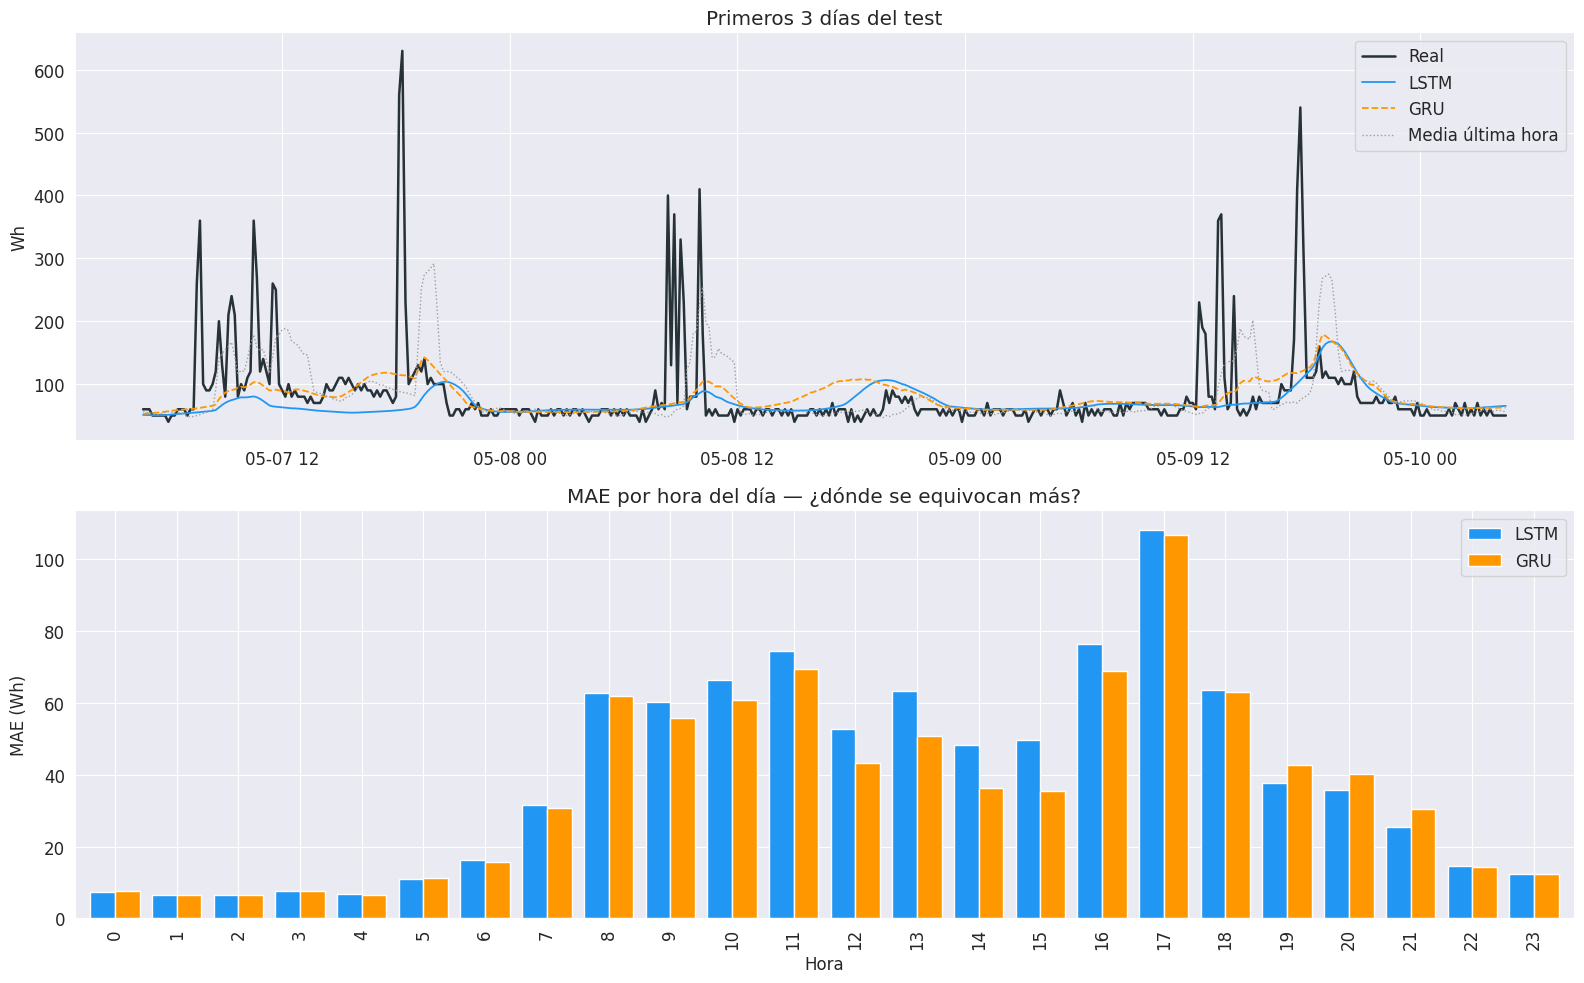

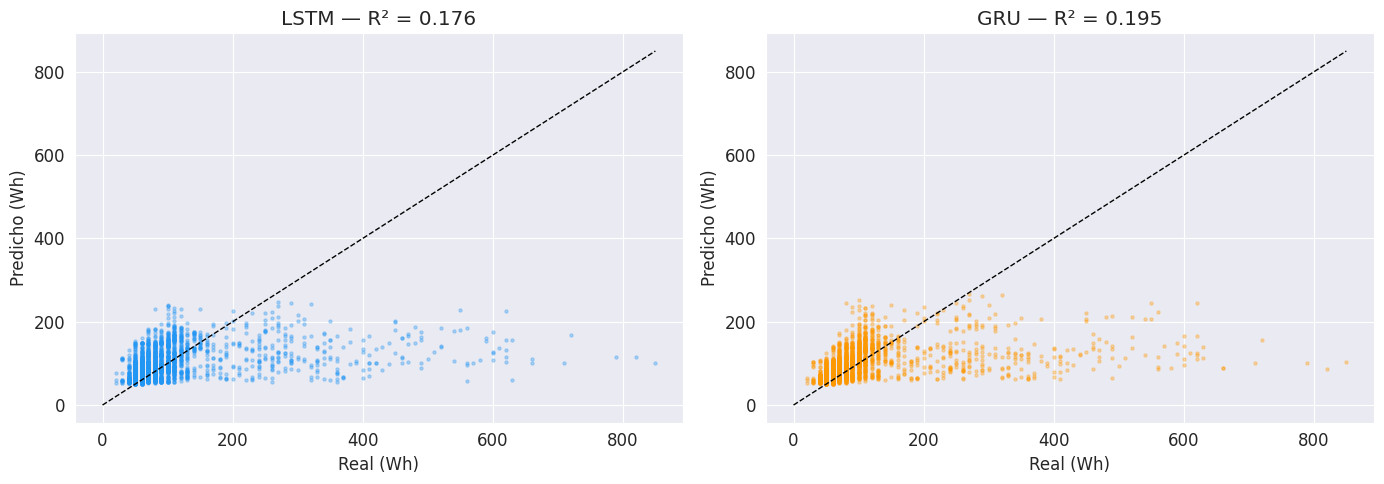

In [13]:
# ============================================================
# 📊 Predicciones vs valores reales
# ============================================================
idx_test = feat.index[i_test:]
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
s = slice(0, 144 * 3)        # 3 días
axes[0].plot(idx_test[s], y_real[s], color=COLORS['actual'], lw=1.8, label='Real')
axes[0].plot(idx_test[s], p_lstm[s], color=COLORS['lstm'], lw=1.3, label='LSTM')
axes[0].plot(idx_test[s], p_gru[s], color=COLORS['gru'], lw=1.3, ls='--', label='GRU')
axes[0].plot(idx_test[s], p_mean1h[s], color=COLORS['naive'], lw=1, ls=':', label='Media última hora')
axes[0].set_title('Primeros 3 días del test'); axes[0].set_ylabel('Wh'); axes[0].legend()

err = pd.DataFrame({'hora': idx_test.hour,
                    'LSTM': np.abs(y_real - p_lstm), 'GRU': np.abs(y_real - p_gru)}).groupby('hora').mean()
err.plot(kind='bar', ax=axes[1], color=[COLORS['lstm'], COLORS['gru']], width=0.8)
axes[1].set_title('MAE por hora del día — ¿dónde se equivocan más?')
axes[1].set_ylabel('MAE (Wh)'); axes[1].set_xlabel('Hora')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (nm, p, key) in zip(axes, [('LSTM', p_lstm, 'LSTM apilado'), ('GRU', p_gru, 'GRU apilado')]):
    ax.scatter(y_real, p, s=5, alpha=0.3, color=COLORS[nm.lower()])
    lim = [0, max(y_real.max(), p.max())]; ax.plot(lim, lim, 'k--', lw=1)
    ax.set_title(f'{nm} — R² = {res[key]["R2"]:.3f}'); ax.set_xlabel('Real (Wh)'); ax.set_ylabel('Predicho (Wh)')
plt.tight_layout(); plt.show()

> 📝 **Interpretación de los gráficos:**
> - **Primeros 3 días del test:** los modelos predicen bien el **consumo base** (~50–60 Wh) pero **no anticipan los picos**, que llegan a 400–630 Wh. Cuando aparece un pico, la predicción sube recién **después**, de forma suave (~100–170 Wh). El modelo aprendió "si hubo actividad, es probable que siga un rato", no cuándo empezará.
> - **MAE por hora del día:**
>   - De madrugada (0–5 h), el error es mínimo (**~7 Wh**): no hay actividad y el consumo es predecible.
>   - El error crece en la **mañana (8–11 h, ~60–75 Wh)** y alcanza su **máximo a las 17 h (~107 Wh)**, justo antes del pico de la cena.
>   - El **GRU se equivoca menos entre las 12 y las 16 h** (por ejemplo, 36 vs 50 Wh a las 15 h). El LSTM es levemente mejor entre las 19 y las 21 h.
> - **Dispersión:** los puntos se concentran en valores bajos, y para consumos reales altos las predicciones quedan muy por debajo de la diagonal. Los modelos **subestiman sistemáticamente los picos**, efecto también de entrenar en escala logarítmica.

---
### 2.7 · Experimento: ¿aportan las variables ambientales?

Entrenamos los **mismos** LSTM y GRU usando solo el historial del consumo (univariado) y comparamos con la versión multivariada.

  LSTM univariado listo (29.8s)
  GRU univariado listo (51.0s)

UNIVARIADO vs MULTIVARIADO (Wh)
Modelo                 MAE (Wh)      RMSE (Wh)     R²       Params     Tiempo (s)
--------------------------------------------------------------------------------
LSTM univariado        36.074        83.956        0.146    118,081    29.8      
LSTM multivariado      39.767        82.487        0.176    132,929    46.4      
GRU univariado         35.108        83.192        0.162    89,665     51.0      
GRU multivariado       37.170        81.529        0.195    100,801    48.1      


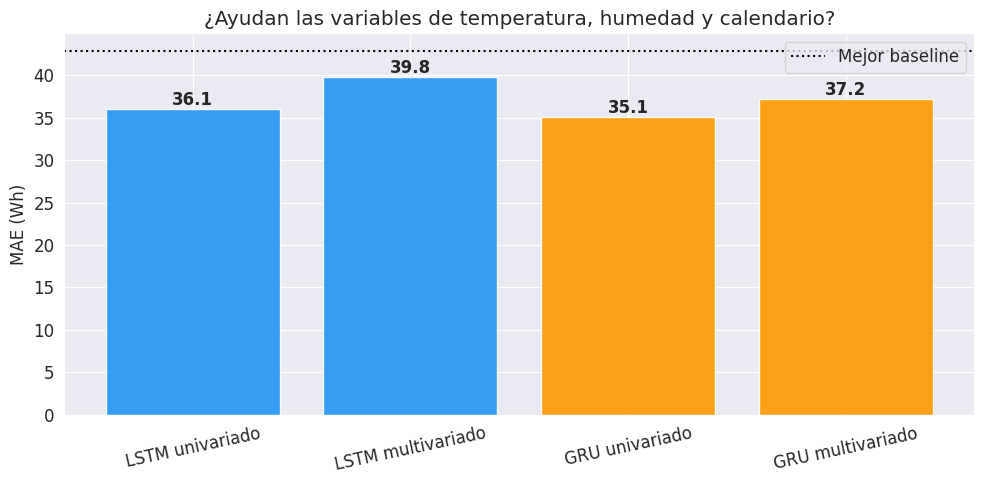

In [14]:
# ============================================================
# 🔍 Univariado vs multivariado
# ============================================================
uni = {}
for cell in ['LSTM', 'GRU']:
    m = build_rnn(cell, (WINDOW, 1), units=(128, 64), dropout=0.2, dense=32)
    _, t = train_model(m, X_tr[:, :, :1], y_tr, val=(X_va[:, :, :1], y_va), epochs=40, batch_size=128)
    p = inv_wh(m.predict(X_te[:, :, :1], verbose=0))
    uni[cell] = {**evaluate_forecast(y_real, p), 'params': m.count_params(), 'time': t}
    print(f'  {cell} univariado listo ({t:.1f}s)')

tabla = {'LSTM univariado':  uni['LSTM'], 'LSTM multivariado': res['LSTM apilado'],
         'GRU univariado':   uni['GRU'],  'GRU multivariado':  res['GRU apilado']}
print('\nUNIVARIADO vs MULTIVARIADO (Wh)')
print_table(tabla, '(Wh)')

fig, ax = plt.subplots(figsize=(10, 5))
names = list(tabla); vals = [tabla[k]['MAE'] for k in names]
ax.bar(names, vals, color=[COLORS['lstm'], COLORS['lstm'], COLORS['gru'], COLORS['gru']],
       alpha=0.9, edgecolor='white')
for i, v in enumerate(vals): ax.text(i, v, f'{v:.1f}', ha='center', va='bottom', fontweight='bold')
ax.axhline(mejor_base, color='k', ls=':', label='Mejor baseline'); ax.legend()
ax.set_ylabel('MAE (Wh)'); ax.set_title('¿Ayudan las variables de temperatura, humedad y calendario?')
plt.xticks(rotation=12); plt.tight_layout(); plt.show()

> 📝 **Interpretación (resultado mixto, importante para la discusión):**
>
> | Modelo | MAE (Wh) | RMSE (Wh) | R² |
> |---|---|---|---|
> | LSTM univariado | 36.07 | 83.96 | 0.146 |
> | LSTM multivariado | 39.77 | **82.49** | **0.176** |
> | GRU univariado | **35.11** | 83.19 | 0.162 |
> | GRU multivariado | 37.17 | **81.53** | **0.195** |
>
> - **Por MAE gana el univariado** (5.9% mejor en GRU y 10.2% en LSTM). **Por RMSE y R² gana el multivariado.**
> - ¿Por qué? El MAE pesa igual todos los errores, y la mayoría de las muestras son de **consumo base**. Ahí las 29 variables extra **agregan ruido** y el modelo univariado, más simple, acierta mejor. El RMSE castiga más los **errores grandes (picos)**, y en esos momentos las variables ambientales **sí ayudan**: por ejemplo, la humedad y la temperatura de la cocina o el baño suben cuando se usan los aparatos.
> - Hay dos razones probables por las que las variables extra no ayudan más:
>   1. **Redundancia:** muchas variables muy correlacionadas entre sí (T6–T_out r = 0.97).
>   2. **Cambio de condiciones:** el test (mayo) es más cálido que el train (enero–abril), así que las variables de temperatura toman valores poco vistos al entrenar.
> - **Conclusión:** agregar variables **no garantiza** mejorar todas las métricas. Haría falta una **selección de variables** (quedarse con `lights`, la hora y unas pocas temperaturas y humedades) para aprovechar lo mejor de ambos enfoques.

---
## 🏁 Resumen

In [15]:
# ============================================================
# 📋 Resumen final
# ============================================================
todo = {**res, 'LSTM univariado': uni['LSTM'], 'GRU univariado': uni['GRU']}
resumen = pd.DataFrame(todo).T[['MAE', 'RMSE', 'R2']].astype(float).round(3)
resumen['Parámetros'] = [todo[k].get('params', '—') for k in todo]
resumen['Tiempo (s)'] = [round(todo[k]['time'], 1) if todo[k].get('time') else '—' for k in todo]
display(resumen)

ganador = 'LSTM' if res['LSTM apilado']['MAE'] < res['GRU apilado']['MAE'] else 'GRU'
print(f'• Menor MAE (multivariado): {ganador}')
print(f'• GRU usa {(1 - gru.count_params()/lstm.count_params())*100:.0f}% menos parámetros y tardó '
      f'{t_gru:.1f}s frente a {t_lstm:.1f}s del LSTM')
for c in ['LSTM', 'GRU']:
    k = f'{c} apilado'
    print(f'• {c}: multivariado vs univariado → {(1 - res[k]["MAE"]/uni[c]["MAE"])*100:+.1f}% en MAE')

,MAE,RMSE,R2,Parámetros,Tiempo (s)
Naive (último valor),46.292,101.658,-0.251,—,—
Naive estac. (t-24h),52.489,109.473,-0.451,—,—
Media última hora,42.806,88.256,0.057,—,—
LSTM apilado,39.767,82.487,0.176,132929,46.4
GRU apilado,37.170,81.529,0.195,100801,48.1
LSTM univariado,36.074,83.956,0.146,118081,29.8
GRU univariado,35.108,83.192,0.162,89665,51.0


• Menor MAE (multivariado): GRU
• GRU usa 24% menos parámetros y tardó 48.1s frente a 46.4s del LSTM
• LSTM: multivariado vs univariado → -10.2% en MAE
• GRU: multivariado vs univariado → -5.9% en MAE


In [ ]:
# Guardamos los resultados de la Parte 2 para la comparación final
res_energy = dict(res)
uni_energy = dict(uni)
print('✅ Resultados de la Parte 2 guardados en res_energy')

### 💡 Conclusiones de la Parte 2
1. **Serie difícil:** el consumo depende de acciones humanas puntuales, por lo que los picos son casi impredecibles 1 hora antes. Los naive tienen **R² negativo** y el mejor modelo llega a **R² = 0.195**. Aun así, **LSTM y GRU superan a todos los baselines** (7.1% y 13.2% de mejora en MAE frente a la media de la última hora).
2. **LSTM vs GRU:** aquí el **GRU gana con claridad**: MAE 37.17 vs 39.77 Wh (−6.5%), mejor RMSE y R², **24.2% menos parámetros**, ~20% más rápido por época y sin el sobreajuste que mostró el LSTM a partir de la época ~10. Con 30 variables y pocos meses de datos, el modelo más simple **generaliza mejor**.
3. **Multivariado vs univariado:** resultado mixto. El univariado tiene **menor MAE** (mejor en el consumo base) y el multivariado **menor RMSE y mayor R²** (mejor en los picos). Las variables ambientales aportan información sobre la actividad en la casa, pero su redundancia y el cambio de estación entre train y test limitan la ganancia.
4. **Transformación log:** redujo la asimetría de 3.39 a 1.19, evitando que unos pocos picos dominen el MSE. Como contrapartida, los modelos tienden a **subestimar los picos**.
5. **Errores por hora:** casi nulos de madrugada (~7 Wh) y máximos en las horas de actividad, con el **pico a las 17 h (~107 Wh)**, antes de la cena.

#### ✅ Checklist Parte 2
| # | Verificación | Estado |
|---|---|---|
| 1 | Grilla regular de 10 min (sin huecos) y eliminación de `rv1`/`rv2` | ✅ |
| 2 | Split cronológico 70/15/15 | ✅ |
| 3 | `MinMaxScaler` ajustado solo en train | ✅ |
| 4 | Target transformado con `log1p` y métricas en Wh | ✅ |
| 5 | Shapes `(samples, 144, 30)` | ✅ |
| 6 | Tres baselines antes de evaluar los modelos | ✅ |
| 7 | Misma arquitectura para LSTM y GRU | ✅ |
| 8 | Experimento univariado vs multivariado | ✅ |

---
# 🏁 PARTE 3: Comparación final — LSTM vs GRU en ambos datasets

,Dataset,Modelo,MAE,RMSE,R²,Mejora vs mejor baseline (%),Parámetros,Tiempo (s)
0,Melbourne (°C),LSTM,1.746,2.226,0.706,10.462,29857,36.1
1,Melbourne (°C),GRU,1.750,2.231,0.704,10.256,22817,14.1
2,Appliances (Wh),LSTM,39.767,82.487,0.176,7.099,132929,46.4
3,Appliances (Wh),GRU,37.170,81.529,0.195,13.166,100801,48.1


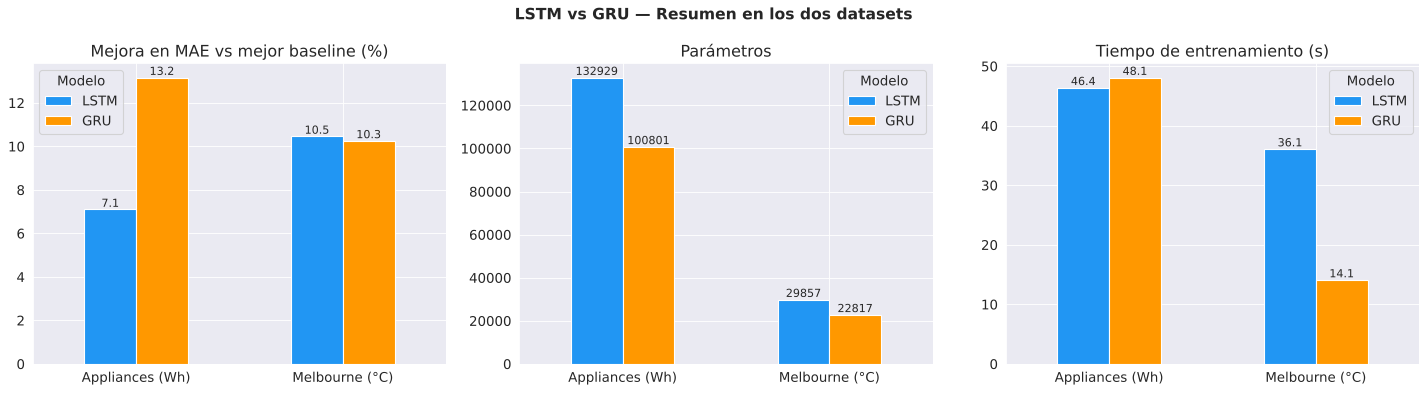

In [ ]:
# ============================================================
# 📋 Comparación global LSTM vs GRU
# ============================================================
casos = [
    ('Melbourne (°C)',  res_melb,   ['Naive (t-1)', 'Naive estac. (t-365)', 'Media móvil 7 días'], ['LSTM', 'GRU']),
    ('Appliances (Wh)', res_energy, ['Naive (último valor)', 'Naive estac. (t-24h)', 'Media última hora'], ['LSTM apilado', 'GRU apilado']),
]
filas = []
for ds, r, bases, mods in casos:
    mejor_base = min(r[b]['MAE'] for b in bases)
    for mk, nombre in zip(mods, ['LSTM', 'GRU']):
        filas.append({'Dataset': ds, 'Modelo': nombre,
                      'MAE': r[mk]['MAE'], 'RMSE': r[mk]['RMSE'], 'R²': r[mk]['R2'],
                      'Mejora vs mejor baseline (%)': (1 - r[mk]['MAE'] / mejor_base) * 100,
                      'Parámetros': r[mk]['params'], 'Tiempo (s)': r[mk]['time']})
comp = pd.DataFrame(filas)
display(comp.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, titulo in zip(axes, ['Mejora vs mejor baseline (%)', 'Parámetros', 'Tiempo (s)'],
                           ['Mejora en MAE vs mejor baseline (%)', 'Parámetros', 'Tiempo de entrenamiento (s)']):
    piv = comp.pivot(index='Dataset', columns='Modelo', values=col)[['LSTM', 'GRU']]
    piv.plot(kind='bar', ax=ax, color=[COLORS['lstm'], COLORS['gru']], rot=0, edgecolor='white')
    for cont in ax.containers:
        ax.bar_label(cont, fmt='%.1f' if col != 'Parámetros' else '%.0f', fontsize=10)
    ax.set_title(titulo); ax.set_xlabel('')
plt.suptitle('LSTM vs GRU — Resumen en los dos datasets', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

### 📝 Interpretación de la comparación final

| Criterio | Melbourne (univariado, diario) | Appliances (multivariado, 10 min) |
|---|---|---|
| ¿Superan al mejor baseline? | Sí: LSTM +10.5%, GRU +10.3% | Sí: LSTM +7.1%, GRU +13.2% |
| Menor error | LSTM, por solo 0.004 °C (empate) | **GRU**, por 2.6 Wh (−6.5%) |
| Parámetros | GRU −23.6% | GRU −24.2% |
| Tiempo total | GRU 2.56× más rápido (convergió en 17 épocas vs 44) | Similar (GRU ~20% más rápido por época, pero entrenó más épocas) |
| Estabilidad | GRU estable con cualquier ventana; LSTM empeora con 90–365 días | LSTM sobreajusta desde la época ~10; GRU estable |

**Verificación de la hipótesis inicial:** *"GRU logra un error similar al de LSTM con menos parámetros y menos tiempo"*
- ✅ **Error similar o mejor:** empate en Melbourne y GRU mejor en Appliances.
- ✅ **Menos parámetros:** ~24% menos en ambos datasets, tal como predice la teoría (2 compuertas vs 3).
- ⚠️ **Menos tiempo:** solo en parte. Con cuDNN en GPU, el costo por época es parecido. La ventaja real del GRU fue **converger antes o generalizar mejor**, no cada época en sí.

## 📋 Conclusiones generales
1. **En ambos datasets, LSTM y GRU superan a los baselines**, pero la ganancia es moderada (7–13% en MAE). Un buen baseline (naive o media móvil) es un rival difícil y **siempre debe calcularse** antes de juzgar un modelo.
2. **El GRU es la mejor opción en esta práctica:** iguala al LSTM en la serie simple (Melbourne) y lo supera en la compleja (Appliances), con ~24% menos parámetros y más estabilidad frente a ventanas largas y sobreajuste. Se confirma la regla de clase: **empezar con GRU y escalar a LSTM solo si hace falta más capacidad**.
3. **La naturaleza de los datos pesa más que la arquitectura:** en Melbourne se explica el ~70% de la varianza porque la temperatura tiene inercia y estacionalidad. En Appliances solo el ~20%, porque el consumo depende de decisiones humanas. Ninguna arquitectura recurrente resuelve la falta de información predictiva.
4. **La preparación de datos fue decisiva:** limpiar el CSV y completar los días faltantes (Melbourne), la transformación logarítmica y la codificación cíclica de la hora (Appliances), el split cronológico y el escalado ajustado solo en train.
5. **Más variables no siempre es mejor:** en Appliances el enfoque multivariado mejoró el RMSE y el R² (picos), pero empeoró el MAE (consumo base). La **selección de variables** es el siguiente paso natural.
6. **Limitación del análisis:** cada modelo se entrenó una sola vez con semilla 42. Diferencias tan pequeñas como la de Melbourne (0.004 °C) no son concluyentes. Para afirmar un ganador habría que repetir el entrenamiento con varias semillas y comparar promedios.

---
### 📚 Fuentes de los datos
- *Daily Minimum Temperatures in Melbourne, Australia, 1981–1990*. Australian Bureau of Meteorology, vía Kaggle (`paulbrabban/daily-minimum-temperatures-in-melbourne`).
- Candanedo, L. M., Feldheim, V., & Deramaix, D. (2017). *Data driven prediction models of energy use of appliances in a low-energy house*. Energy and Buildings, 140, 81–97. Vía Kaggle (`loveall/appliances-energy-prediction`) / UCI Machine Learning Repository.